In [1]:
%load_ext autoreload
%autoreload 2
    
from domino.data.data import *
from scipy import stats
from domino.models.domino_models import DominoSingleOutput
from domino.utils import tools
import matplotlib.pyplot as plt
from domino.utils.tools import seq_from_df
import pandas as pd
import seaborn as sns
import os
plt.rcdefaults()
plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'
import fanc
import fanc.plotting as fancplot

from domino.utils.plotting import plot_attribution

from modiscolite.report import generate_tomtom_dataframe
import h5py

import sys
sys.path.append('/scratch/gpfs/PRITYKIN/brendan/domino/python_modules')

from load_modisco import *
from generic_plotting_functions import *
from plot_attributions_and_fimo import *

In [2]:
import json
with open('all_nc14_pattern_to_target_dict.json', 'r') as f:
    npatterns2targets = json.load(f)
targets2npatterns = {v[0]:k for k,v in npatterns2targets.items() if 'neg' in k}

with open('cluster_annotations.json', 'r') as f:
    cluster2annotation = json.load(f)

In [3]:
# get pattern CWM and PPMs with 4 flanking bps
TFMODISCO_WINDOW=600
NUM_FLANKING_BASES=4

out_folder = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/ism_report_1_cutoff/'
h5_file = f"{out_folder}/modisco_results_{TFMODISCO_WINDOW}bp.h5"

pattern_cwms, pattern_ppms = get_pattern_info(h5_file, NUM_FLANKING_BASES)
pattern_attr = get_average_contribution_df(pattern_cwms)

In [4]:
modisco_h5py = f"{out_folder}/modisco_results_{TFMODISCO_WINDOW}bp.h5"
output_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/tmp'
meme_motif_db = f"/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/JASPAR2024_CORE_insects_non-redundant_pfms_meme.txt"
is_writing_tomtom_matrix = False 
pattern_groups = ['pos_patterns', 'neg_patterns']
top_n_matches=3
tomtom_exec = "tomtom"
trim_threshold=0.3
trim_min_length=3

results = {'pattern': [], 'num_seqlets': [], 'modisco_cwm_fwd': [], 'modisco_cwm_rev': []}
img_path_suffix = f'{out_folder}/ism_report_{TFMODISCO_WINDOW}bp'
with h5py.File(modisco_h5py, 'r') as modisco_results:
    for name in pattern_groups:
        if name not in modisco_results.keys():
            continue

        metacluster = modisco_results[name]
        key = lambda x: int(x[0].split("_")[-1])
        for pattern_name, pattern in sorted(metacluster.items(), key=key):
            num_seqlets = pattern['seqlets']['n_seqlets'][:][0]
            pattern_tag = f'{name}.{pattern_name}'

            results['pattern'].append(pattern_tag)
            results['num_seqlets'].append(num_seqlets)
            results['modisco_cwm_fwd'].append(os.path.join(img_path_suffix, 'trimmed_logos', f'{pattern_tag}.cwm.fwd.png'))
            results['modisco_cwm_rev'].append(os.path.join(img_path_suffix, 'trimmed_logos', f'{pattern_tag}.cwm.rev.png'))

patterns_df = pd.DataFrame(results)
tomtom_df = generate_tomtom_dataframe(modisco_h5py, output_dir, meme_motif_db, is_writing_tomtom_matrix, pattern_groups)
patterns_df = pd.concat([patterns_df, tomtom_df], axis=1)

final_patterns_df = patterns_df[['pattern', 'num_seqlets', 'match0', 'qval0',	'match1',	'qval1', 'match2',	'qval2']]
avg_attrs = []
for name, cwm in pattern_cwms.items():
    assert(round(cwm['fwd'].mean(), 5) == round(cwm['rev'].mean(), 5))
    # print(cwm['fwd'].shape[0])
    avg_attrs.append(cwm['fwd'].sum()/cwm['fwd'].shape[0])

final_patterns_df['avg_attr'] = avg_attrs
final_patterns_df = final_patterns_df.sort_values('avg_attr').reset_index(drop=True)

# get best match to target
from tangermeme.io import read_meme
import logomaker

motifs = read_meme(meme_motif_db)
jaspar2pwm = dict()
for key, pwm in motifs.items():
    motif_code, motif_name = key.split(' ')
    jaspar2pwm[motif_code] = {'pwm': pwm.numpy(), 'name': motif_name}
names = []
for i, row in final_patterns_df.iterrows():
    match = row.match0
    if match in jaspar2pwm:
        name = jaspar2pwm[match]['name']
        names.append(name)
    else:
        names.append(None)
final_patterns_df['target'] = names

/tmp/ipykernel_3624397/143398203.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_patterns_df['avg_attr'] = avg_attrs


In [5]:
def plot_weights(array, ax, pattern_name=None, num_seqlets=None, q_val=None):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    df = pd.DataFrame(array, columns=['A', 'C', 'G', 'T'])
    df.index.name = 'pos'

    crp_logo = logomaker.Logo(df, ax=ax)
    crp_logo.style_spines(visible=False)
    crp_logo.style_spines(visible=False)
    ax.set_axis_off()
    if pattern_name and num_seqlets:
        ax.set_title(f'{pattern_name} (num_seqlets={num_seqlets}) {round(q_val,3)}')

def compute_per_position_ic(ppm, background, pseudocount):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    alphabet_len = len(background)
    ic = ((np.log((ppm+pseudocount)/(1 + pseudocount*alphabet_len))/np.log(2))
          *ppm - (np.log(background)*background/np.log(2))[None,:])
    return np.sum(ic,axis=1)

def make_logo(ppm):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    background = np.array([0.29, 0.21, 0.21, 0.29])
    ic = compute_per_position_ic(ppm, background, 0.001)
    return ppm*ic[:, None]

def trim_cwm(cwm, trim_threshold=0.3, FLANKING_BASES=1):
    # get abs score of each base pair (so this will be of length 30)
    score = np.sum(np.abs(cwm), axis=1) 
    
    # cut off anything less than 30% of max score
    trim_thresh = np.max(score) * trim_threshold 
    pass_inds = np.where(score >= trim_thresh)[0]

    # include flanking 4 bases left and right
    start, end = max(np.min(pass_inds) - FLANKING_BASES, 0), min(np.max(pass_inds) + FLANKING_BASES + 1, len(score) + 1)
    trimmed_cwm = cwm[start:end]
    
    return trimmed_cwm

## Define final set of boundaries

In [6]:
nc14_model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu'
final_nc14_boundaries_df = pd.read_csv(f'{nc14_model_dir}/final_nc14_boundaries_df.bound_score_gt_1.csv')


In [7]:
ism_dir = os.path.join(nc14_model_dir, 'numpy_arrs')
ism_attr = np.load(os.path.join(ism_dir, 'windowed_attributions.bound_score_gt_1.npy'))

print(ism_attr.shape)

tag2idx = dict()
for i, name in enumerate(pattern_attr.index):
    tag2idx[name] = i + 1

idx2tag = {v:k for k,v in tag2idx.items()}

# getting all the metadata for each seqlet pattern, including contribution scores, example_idx, start, end, etc.
modisco_results = h5py.File(f"{out_folder}/modisco_results_{TFMODISCO_WINDOW}bp.h5","r")

# maps index IDX to seqlet data
seqlets_data = {}
names = ['neg_patterns', 'pos_patterns'] 
for name in names:
    metacluster = modisco_results[name]
    key = lambda x: int(x[0].split("_")[-1])
    for pattern_name, pattern in sorted(metacluster.items(), key=key):
        tag = '{}.{}'.format(name, pattern_name)
        seq_dict = dict()
        for key in pattern['seqlets']:
            seq_dict[key] = pattern['seqlets'][key][:]
        if tag in tag2idx:
            tag = tag2idx[tag] # get the index corresponding to the pattern if it exists and get all the data associated with it
        seqlets_data[tag] = seq_dict

modisco_results.close()

(14622, 4, 600)


In [8]:
# counts is how many instances does boundary have of this motif
attr_mat, counts_mat = np.zeros((len(ism_attr), len(pattern_attr))), np.zeros((len(ism_attr), len(pattern_attr)))

# for each pattern in seqlets_data
for pattern_idx, data in seqlets_data.items():
    contrib_scores = data['contrib_scores'] 
    example_idx = data['example_idx']
    
    # for each motif instance, add count
    # also get all trimmed cwm seqlets and get sum of attribution
    for ex_idx, cwm in zip(example_idx, contrib_scores):
        trimmed_cwm = trim_cwm(cwm, trim_threshold=0.3, FLANKING_BASES=1) 
        summed_attr = trimmed_cwm.sum()
        
        # update matrix
        attr_mat[ex_idx, pattern_idx - 1] += summed_attr
        counts_mat[ex_idx, pattern_idx - 1] += 1

print('before filtering', attr_mat.shape)
print('before filtering', counts_mat.shape)

even_row_sum = counts_mat[0::2]
odd_row_sum = counts_mat[1::2]
counts_mat_combined = even_row_sum + odd_row_sum

even_row_sum = attr_mat[0::2]
odd_row_sum = attr_mat[1::2]
attr_mat_combined = even_row_sum + odd_row_sum

attr_mat_final = attr_mat_combined / 2

print('Number of seqlets for each pattern:')
print(counts_mat_combined.sum(axis=0))
print('Yay this matches the number of seqlets for each pattern! (see TFModisco results PDF)')

orig_mat = pd.DataFrame(attr_mat_final, columns=final_patterns_df.pattern)
print('clustergram shape (all boundaries > 1):', orig_mat.shape)
print(np.array_equal(counts_mat_combined.sum(axis=0), final_patterns_df.num_seqlets))


before filtering (14622, 63)
before filtering (14622, 63)
Number of seqlets for each pattern:
[  26. 2397. 1276.  205. 3376.   44.  620.  280.  229.  188. 1134. 1517.
  325.  810.  695.  265. 1800.  242.   88.   55.  573.   40.  303.  180.
   27.  352.   30.  294.   32.  510.   20. 2990.   29.   81.  522.   20.
   55.   64.   29.  129.   31.   74.  124.   88.   42.   33.   67.   21.
   65.   49.   39.   66.   35.   27.   57.   29.  168.   50.   79.   97.
  270.  110.   41.]
Yay this matches the number of seqlets for each pattern! (see TFModisco results PDF)
clustergram shape (all boundaries > 1): (7311, 63)
True


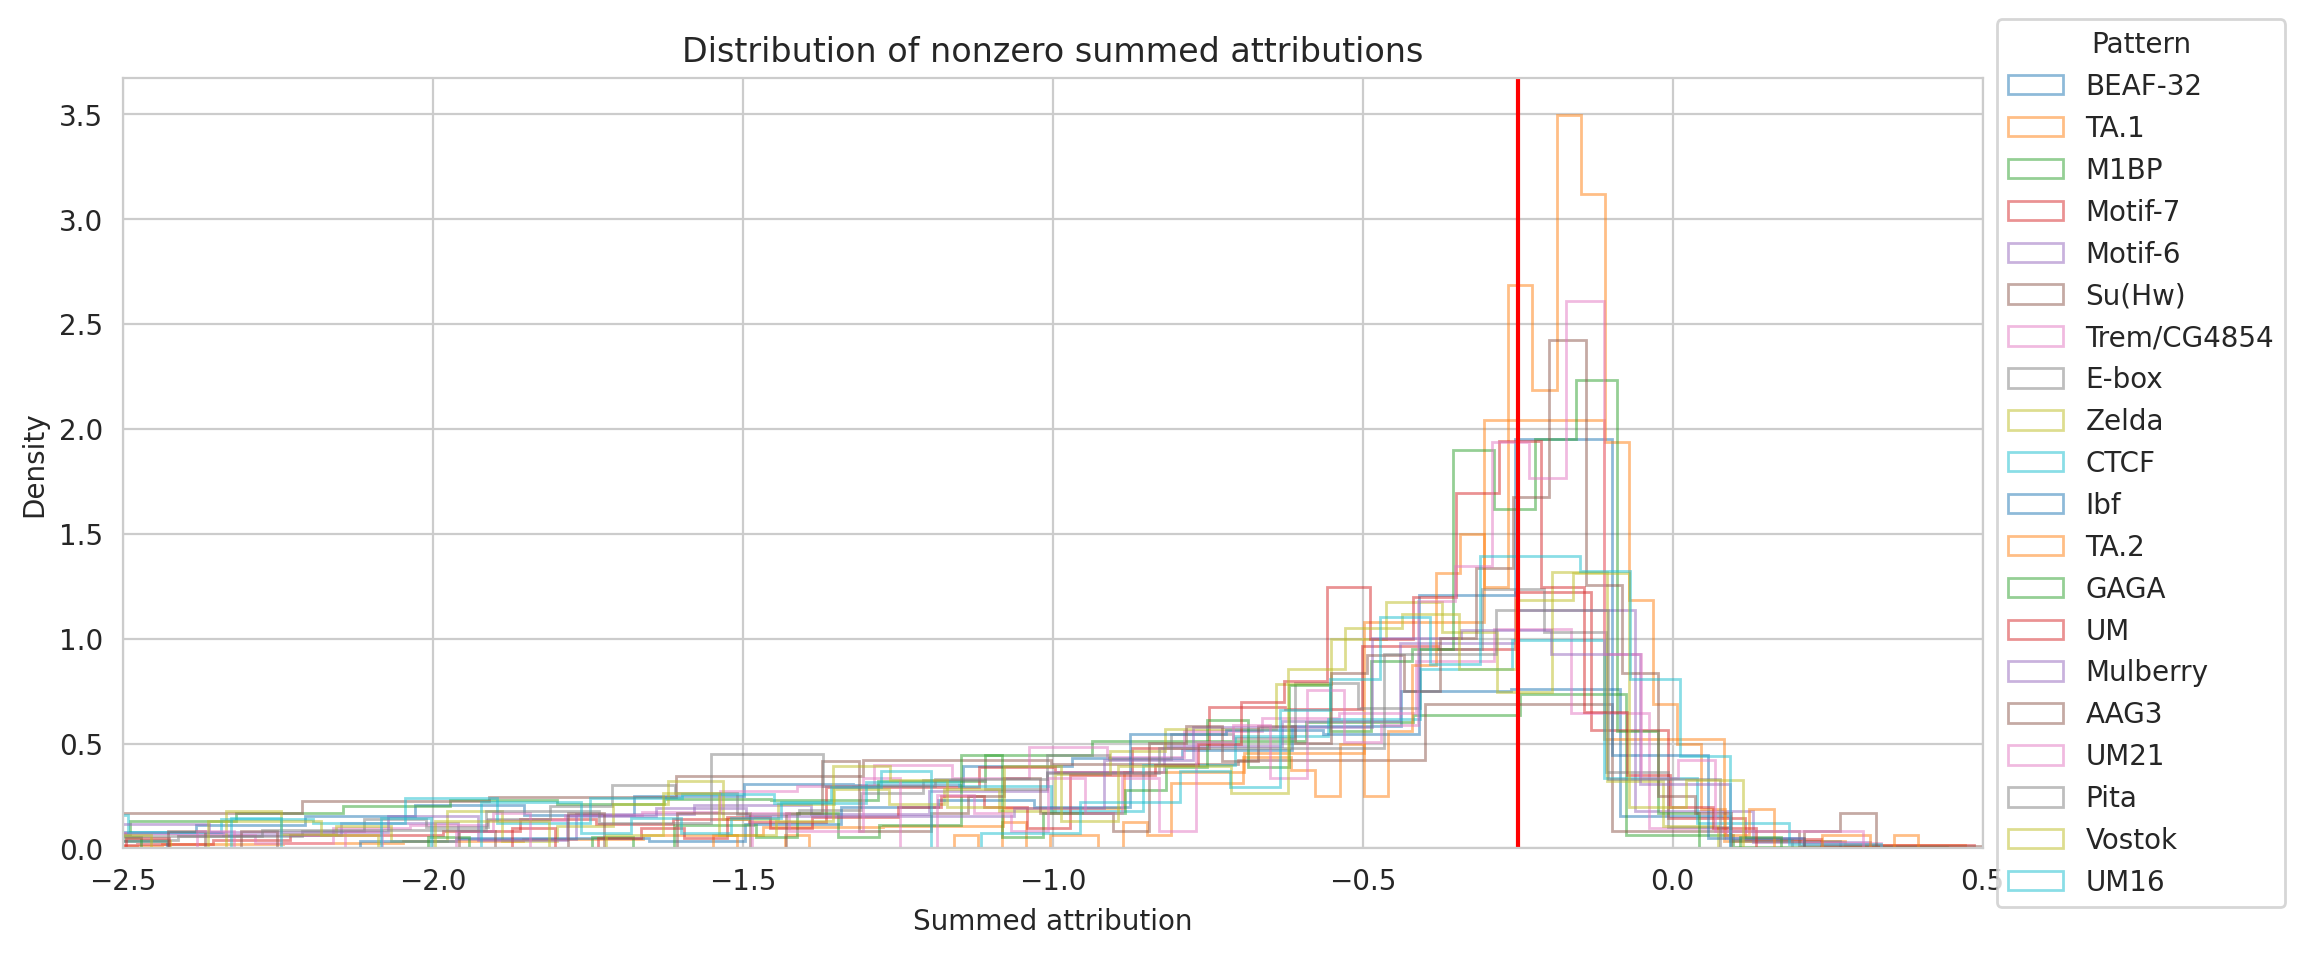

In [9]:
orig_mat_neg = orig_mat.loc[:, orig_mat.columns.str.contains('neg')]
neg_only_final_patterns_df = final_patterns_df.query('pattern.str.contains("neg")')
# nonzero rows with negative patterns
nonzero_rows_df = orig_mat_neg[(orig_mat_neg != 0).any(axis=1)]

%matplotlib inline
plt.figure(figsize=(12,5))
columns = [f'neg_patterns.pattern_{i}' for i in range(20)]
for col in columns[0:20]:
    plt.hist(nonzero_rows_df[col][nonzero_rows_df[col] != 0], histtype='step', density=True, bins=50, alpha=0.5, label=npatterns2targets[col])
plt.axvline(-0.25, c='red')
plt.title('Distribution of nonzero summed attributions')
plt.ylabel('Density')
plt.xlabel('Summed attribution')
plt.xlim(-2.5, 0.5)
plt.legend(title='Pattern', loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

In [10]:
# ALL NEGATIVE MOTIFS IN 2C
motifs_for_synergy = pd.read_csv('../fig6_synergy/nc14_motifs_for_synergy.csv')
final_neg_motifs = motifs_for_synergy.pattern.tolist()
len(final_neg_motifs)
print([npatterns2targets[c][0] for c in orig_mat_neg.columns])

['M1BP', 'Su(Hw)', 'M1BP-alt', 'BEAF-32', 'UIM', 'CTCF', 'Pita', 'Pita-long', 'Brk', 'Trem/CG4854', 'Motif-6', 'Mulberry', 'E-box', 'Zelda', 'Vostok', 'Motif-7', 'UM16', 'UM17', 'UIM', 'Ibf', 'UIM', 'AAG3', 'UM20', 'UIM', 'UM', 'UIM', 'UM21', 'UIM', 'GAGA', 'UIM', 'TA.1', 'UIM', 'UIM', 'TA.2', 'UIM', 'UIM']


In [11]:
GLOBAL_CUTOFF = -0.25

orig_mat_neg = orig_mat.loc[:, final_neg_motifs]
neg_only_final_patterns_df = final_patterns_df.query('pattern.isin(@final_neg_motifs)')

# nonzero rows
nonzero_rows_df = orig_mat_neg[(orig_mat_neg != 0).any(axis=1)]
# negative rows
negative_rows_df = orig_mat_neg[(orig_mat_neg < 0).any(axis=1)]
# active rows (all boundaries with at least one active motif)
active_rows_df = orig_mat_neg[(orig_mat_neg < GLOBAL_CUTOFF).any(axis=1)]
# # ordering by frequency
freq_ordering = (active_rows_df != 0).sum(axis=0).sort_values(ascending=False).index
# # nonzero rows sorted by frequency of attribution 
active_rows_df_sorted = active_rows_df[freq_ordering]
# all negative boundaries that are active (boolean)
active_rows_boolean_df = active_rows_df_sorted < GLOBAL_CUTOFF

print('Original Matrix:', orig_mat_neg.shape)
print('# Negative Motifs =', neg_only_final_patterns_df.shape[0])
print('Boundaries with nonzero attributions for any negative motif:', nonzero_rows_df.shape)
print('Boundaries with negative attributions for any negative motif:', negative_rows_df.shape)
print('Boundaries with at least one strong negative attribution for any negative motif', active_rows_df.shape)


Original Matrix: (7311, 24)
# Negative Motifs = 24
Boundaries with nonzero attributions for any negative motif: (4778, 24)
Boundaries with negative attributions for any negative motif: (4766, 24)
Boundaries with at least one strong negative attribution for any negative motif (4289, 24)


In [12]:
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage

def make_final_clustergram(N, cluster_args, filter_active_rows=True, show_clustergram=False):
    row_metric, row_method = cluster_args
    top_N_cols = active_rows_df_sorted.columns[:N]
    clustergram_matrix = active_rows_df_sorted[top_N_cols]
    print('before filtering', clustergram_matrix.shape)
    if filter_active_rows:
        # filter for active rows
        clustergram_matrix = clustergram_matrix[(clustergram_matrix < GLOBAL_CUTOFF).any(axis=1)]
        print('after filtering', clustergram_matrix.shape)

    if show_clustergram:
        row_linkage = linkage(pdist(clustergram_matrix, metric=row_metric), method=row_method)   # DNA: Euclidean + Average
        col_linkage = linkage(pdist(clustergram_matrix.T, metric="cosine"), method="average")  # Proteins: Correlation + Average
        
        g = sns.clustermap(clustergram_matrix, col_cluster=True, row_cluster=True, figsize=(5, 9), 
                           cmap='RdBu', center=0, vmin=-1, vmax=0.25, xticklabels=1, yticklabels=False,
                           row_linkage=row_linkage, col_linkage=col_linkage, dendrogram_ratio=(0, 0.05),
                           cbar_kws={"orientation": "horizontal"})
        
        labs = [label.get_text() for label in g.ax_heatmap.get_xticklabels()]
        g.ax_heatmap.set_xticklabels([npatterns2targets[x] for x in labs], 
                                     rotation=90, fontsize=10)
        
        cbar = g.cax
        # Reposition and rotate the colorbar
        cbar.set_position([0.3, 0.1, 0.4, 0.02])  # [left, bottom, width, height]
        cbar.xaxis.set_ticks_position("bottom")
        cbar.xaxis.set_label_position("bottom")
        
        plt.suptitle(f'{row_metric} distance + {row_method} linkage', y=1.005)
        
        # plt.savefig("figure_plots/fig2e.pdf", format="pdf")
        plt.show()

    return clustergram_matrix

In [13]:
clustergram_matrix = nonzero_rows_df < GLOBAL_CUTOFF
clustergram_matrix = clustergram_matrix[(clustergram_matrix != 0).any(axis=1)]

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import warnings
from tqdm import tqdm
warnings.filterwarnings("ignore", category=FutureWarning)

top_N_cols = active_rows_df_sorted.columns
clustergram_matrix = nonzero_rows_df[top_N_cols] < GLOBAL_CUTOFF
clustergram_matrix = clustergram_matrix[(clustergram_matrix != 0).any(axis=1)]
X_scaled = StandardScaler().fit_transform(clustergram_matrix)

inertias = []
K = range(2, 75)

for k in tqdm(K):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_) 

100%|██████████| 73/73 [00:15<00:00,  4.61it/s]


/tmp/ipykernel_3309607/361802662.py:6: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "bo-" (-> color='b'). The keyword argument will take precedence.
  ax.plot(K, inertias, 'bo-', ms=2, c='black')


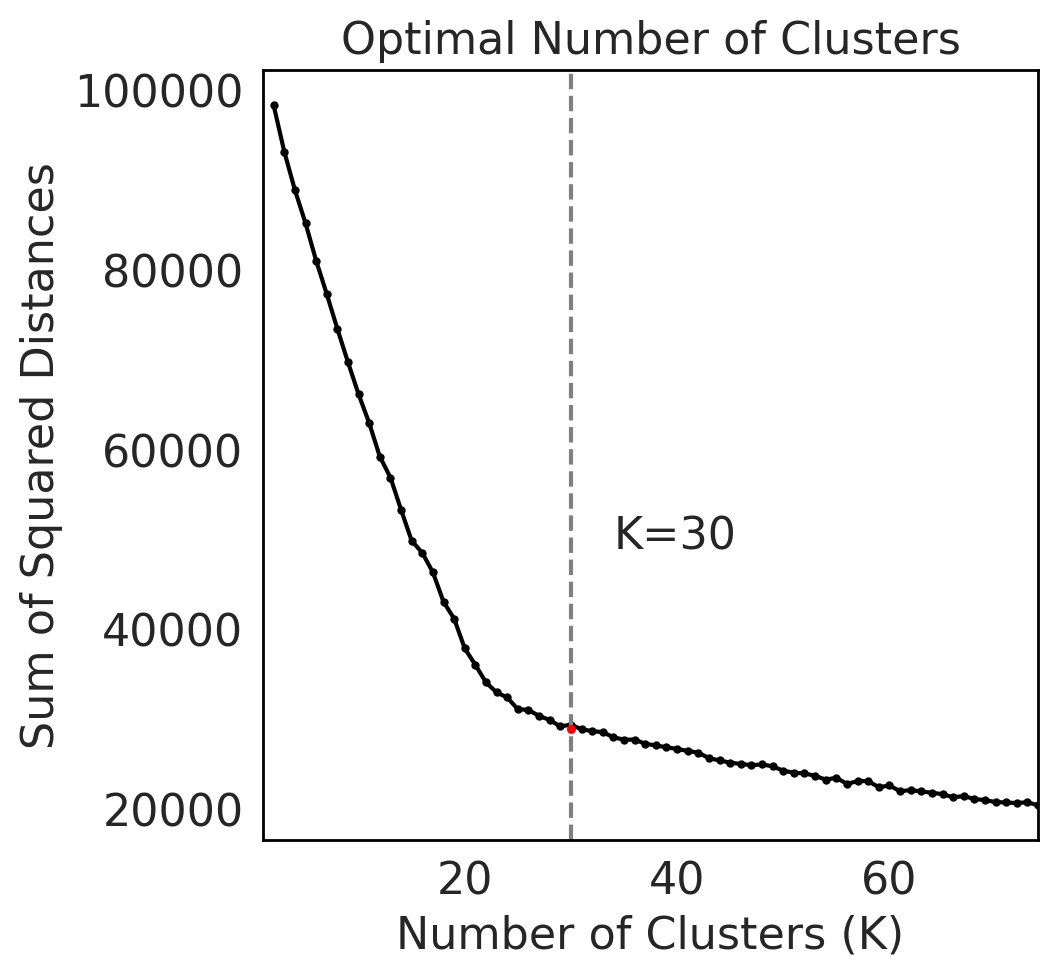

In [36]:
old_rc = plt.rcParams.copy()
plt.rcParams['font.size'] = 16

fig, ax = plt.subplots(1, 1, figsize=(5, 5))
K = range(2, 75)
ax.plot(K, inertias, 'bo-', ms=2, c='black')
ax.scatter([30], [inertias[29]], c='red', s=5, zorder=4)
ax.set_xlabel('Number of Clusters (K)')
ax.set_ylabel('Sum of Squared Distances')
ax.set_title('Optimal Number of Clusters', fontsize=16)
ax.set_xlim([1, 74])
ax.axvline(30, linestyle='--', c='gray')
ax.text(34, inertias[29] + 20000, 'K=30')
ax.grid(False)
for spine in ax.spines:  
    ax.spines[spine].set_color('black')  
    ax.spines[spine].set_linewidth(1)  # Decrease spine thickness
plt.show()
plt.rcParams.update(old_rc)

before filtering (4289, 24)
after filtering (4289, 24)


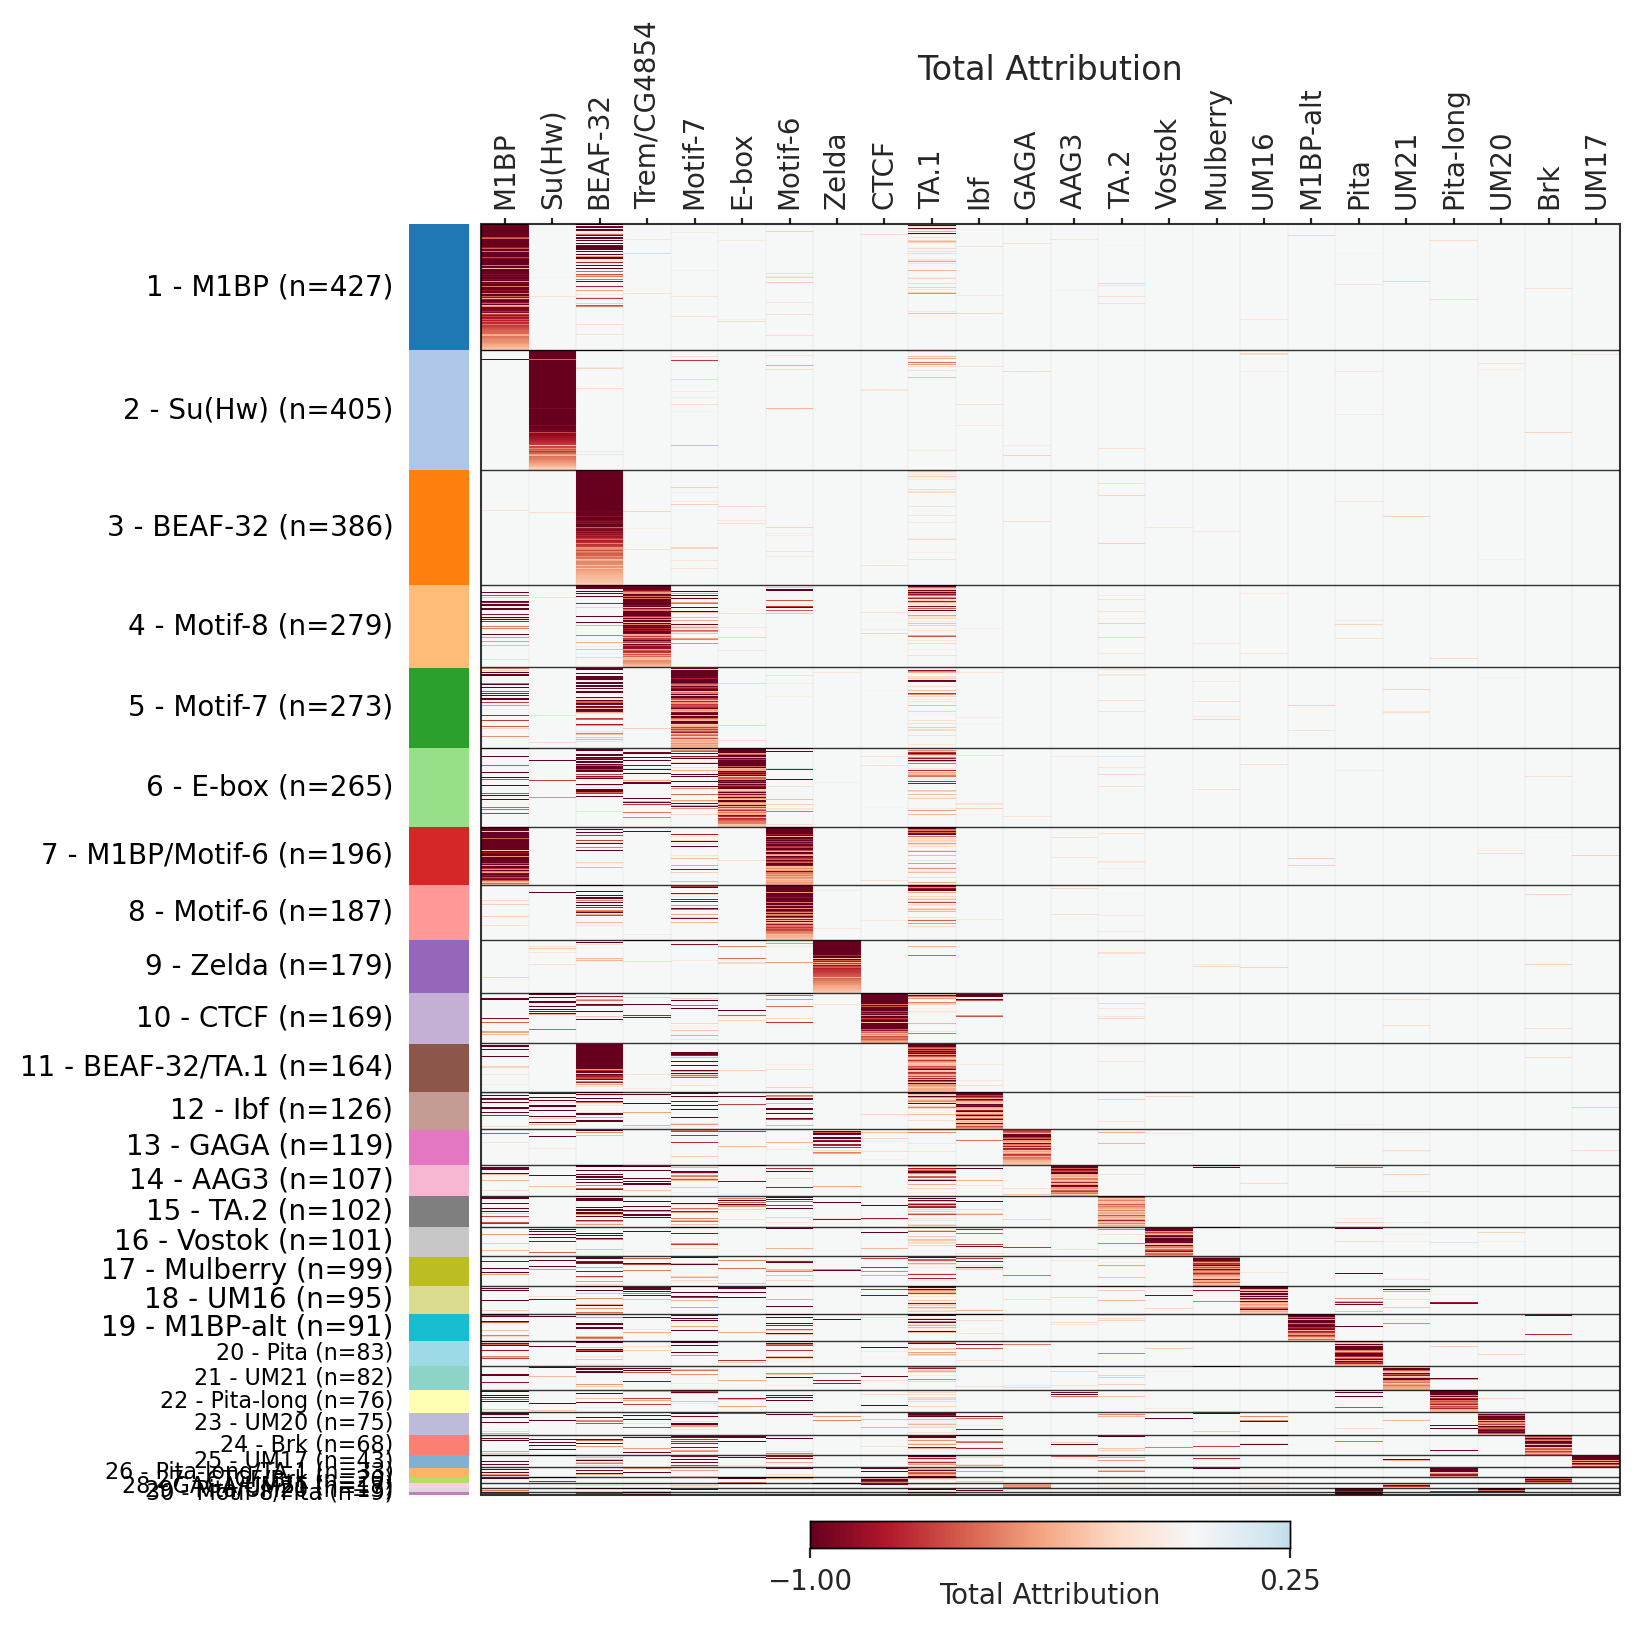

In [14]:
from matplotlib.colors import ListedColormap
from matplotlib.cm import get_cmap
import matplotlib.patches as patches
import matplotlib.patches as mpatches
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

K = 30

clustergram_matrix = nonzero_rows_df < GLOBAL_CUTOFF
clustergram_matrix = clustergram_matrix[(clustergram_matrix != 0).any(axis=1)]

X_scaled = StandardScaler().fit_transform(clustergram_matrix)

kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
kmeans.fit(X_scaled)  

labels = kmeans.labels_
labels = pd.Series(labels)

cluster_sizes = labels.value_counts().sort_values(ascending=False)
label_map = {old: new for new, old in enumerate(cluster_sizes.index)}
new_labels = labels.map(label_map)

sorted_labels = new_labels.sort_values()
sorted_idxs = sorted_labels.index


# GENERATE CLUSTERMAP
top_N_cols = active_rows_df_sorted.columns
clustergram_matrix = active_rows_df_sorted[top_N_cols]
print('before filtering', clustergram_matrix.shape)
clustergram_matrix_filtered = clustergram_matrix[(clustergram_matrix < GLOBAL_CUTOFF).any(axis=1)]
print('after filtering', clustergram_matrix_filtered.shape)
clustergram_sorted_matrix = clustergram_matrix_filtered.iloc[sorted_idxs]

tmp = clustergram_sorted_matrix.copy()
tmp['cluster'] = sorted_labels.tolist()

grouped = tmp.groupby('cluster')
column_order = []
used_columns = set()
for cat in sorted(labels.unique()):
    # for each cluster, count the number of elements with number of active boundaries across all columns
    col_sums = (grouped.get_group(cat) < GLOBAL_CUTOFF).sum()
    sorted_cols = col_sums.sort_values(ascending=False).index.tolist() 
    # print(npatterns2targets[sorted_cols[0]])
    if sorted_cols[0] not in ['cluster'] and sorted_cols[0] not in used_columns:
        column_order.append(sorted_cols[0])
        used_columns.add(sorted_cols[0])
column_order.extend(list(set(top_N_cols) - set(column_order)))
        
tmp['row_sum'] = tmp.drop(columns='cluster').sum(axis=1)
sorted_df = (
    tmp.sort_values(['cluster', 'row_sum'], ascending=[True, True]).drop(columns=['row_sum', 'cluster'])
)
clustergram_sorted_matrix = sorted_df
clustergram_sorted_matrix = clustergram_sorted_matrix[column_order]


tab20_colors = list(plt.get_cmap('tab20').colors)
set3_colors = sns.color_palette("Set3", 15)
colors_K = tab20_colors + set3_colors
cluster_colors = colors_K


col_colors = sorted_labels.map(lambda x: colors_K[x]).tolist()

vmin, vmax=-1, 0.25
g = sns.clustermap(clustergram_sorted_matrix, col_cluster=False, row_cluster=False, figsize=(6, 9), 
                   cmap='RdBu', center=0, vmin=vmin, vmax=vmax, xticklabels=1, yticklabels=False,
                   dendrogram_ratio=(0, 0.05), rasterized=True,
                   cbar_kws={"orientation": "horizontal"}, row_colors=col_colors, colors_ratio=5e-6)  # discrete color annotations on columns)

xlabs = [label.get_text() for label in g.ax_heatmap.get_xticklabels()]
g.ax_heatmap.set_xticklabels([npatterns2targets[x][0] for x in xlabs], 
                             rotation=90, fontsize=10)
g.ax_heatmap.xaxis.set_ticks_position('top')        # Move ticks to top
g.ax_heatmap.xaxis.set_label_position('top')        # Move axis label to top (if any)
g.ax_heatmap.tick_params(axis='x', bottom=False, length=2)
g.ax_heatmap.set_xlabel('')  # Hide x-axis label

# vertical lines between columns
for x in range(1, clustergram_sorted_matrix.shape[1]):
    g.ax_heatmap.axvline(x, color='gray', lw=0.03)
    
cbar = g.cax
cbar.set_position([0.3, 0.21, 0.4, 0.015])  # [left, bottom, width, height]
pos = g.ax_row_colors.get_position().bounds
new_pos = [pos[0] - 0.06, pos[1], pos[2] + 0.05, pos[3]]  # double the width, for example
g.ax_row_colors.set_position(new_pos)

row_groups = sorted_labels.reset_index(drop=True)
row_colors = pd.Series(colors_K[:K])
row_colors.index = np.arange(K)
ordered_groups = row_groups
boundaries = ordered_groups[ordered_groups != ordered_groups.shift(1)].index.tolist()
for b in boundaries[1:]:
    g.ax_heatmap.hlines(b - 0.5, *g.ax_heatmap.get_xlim(), colors='black', linewidth=0.5, alpha=0.8)

cbar.set_xticks([-1, 0.25])
cbar.xaxis.set_ticks_position("bottom")
cbar.xaxis.set_label_position("bottom")
cbar.set_xlabel("Total Attribution", labelpad=-5)
for spine in cbar.spines.values():
    spine.set_visible(True)
    spine.set_edgecolor('black')
    spine.set_linewidth(0.5)

# Add bounding box around the heatmap
pos = g.ax_heatmap.get_position()
rect = patches.Rectangle(
    (pos.x0, pos.y0),           # lower-left corner
    pos.width, pos.height,      # width and height
    linewidth=0.75,
    alpha=0.8,
    edgecolor='black',
    facecolor='none',
    transform=g.fig.transFigure,  # figure coordinates
    zorder=10
)
g.fig.patches.append(rect)


unique_groups = list(row_groups.unique())
cluster_sizes = sorted_labels.value_counts()
cluster_ids = {grp: f'{cluster2annotation[str(grp)]} (n={cluster_sizes[i]})' for i, grp in enumerate(unique_groups)}

# Figure out the y position (in axes fraction) of each group in the color strip
n_rows = len(ordered_groups)
group_y_frac = {}

for grp in unique_groups:
    members = ordered_groups[ordered_groups == grp].index.tolist()
    if members:
        avg_index = sum(members) / len(members)
        y_frac = 1 - (avg_index / n_rows)  # top = 1
        group_y_frac[grp] = y_frac
    
    
# Plot labels and lines directly on the row_colors axis
ax = g.ax_row_colors

for grp in unique_groups:
    y = group_y_frac[grp]
    color = row_colors[grp]
    label = cluster_ids[grp]

    # Draw line from color patch to label
    ax.annotate(
        '', xy=(0.0, y), xycoords='axes fraction',
        xytext=(0.0, y), textcoords='axes fraction',
        # arrowprops=dict(arrowstyle='-', lw=1, color='black')
    )

    # Add text label
    fontsize = 8 if grp >= 19 else 10
    ax.text(
        -0.25, y, label,
        transform=ax.transAxes,
        va='center', ha='right',
        fontsize=fontsize, color='black'
    )

plt.suptitle(f'Total Attribution', y=1.04)
plt.savefig("plots/clustergram.pdf", format="pdf", dpi=300, bbox_inches='tight')
plt.show()

## Clustermap

In [17]:
bound_df = final_nc14_boundaries_df.drop_duplicates(['chrom', 'start', 'end', 'bound_score', 'demeaned_ins_score_1']).reset_index(drop=True)
CP190_bbi = bbi.open('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/run_all_chip_seq/bigwig/CP190.bw')
bound_df['CP190'] = CP190_bbi.stackup(bound_df.chrom, bound_df.start, bound_df.end, bins=1)
bdf_plot = bound_df.iloc[clustergram_sorted_matrix.index].copy() # only positive direction since 
bdf_plot['cluster'] = sorted_labels.tolist()

In [20]:
import bbi

chip_dir='/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/run_all_chip_seq/bigwig/'
target2bbi = dict()
other_fns = [
    'M1BP.bw',
    'suHw.bw',
    'BEAF-32.bw',
    'Trem.bw',
    'CG4854.bw',
    'Zelda.bw',
    'CTCF.bw',
    'Ibf1.bw',
    'Ibf2.bw',
    'Trl.bw', 
    'CG17385.bw', 
    'Vostok.bw',
    'Mulberry.bw',
    'Pita.bw',
    'CP190.bw'    
]

for fn in other_fns: 
    if len(fn.split('.')) <= 2:
        target = fn.split('.')[0]
        target2bbi[target] = bbi.open(os.path.join(chip_dir, fn))
        continue
    target = fn.split('.')[2]
    if target == "RNA_polymerase_II": 
        target = "PolII"
    target2bbi[target] = bbi.open(os.path.join(chip_dir, fn))

In [21]:
from matplotlib.colors import LinearSegmentedColormap

def make_colormap_from_rgb(color_rgb, factor=1):
    color_rgb = tuple(round(c * factor, 3) for c in color_rgb)
    return LinearSegmentedColormap.from_list(
        'white_to_rgb',
        [(1, 1, 1), color_rgb],
        N=256
    )

def make_colormap_from_hex(color_hex):
    """Creates a colormap from white (low) to a saturated color (high)."""
    return LinearSegmentedColormap.from_list(
        f'white_to_{color_hex}',
        ['#ffffff', color_hex],
        N=256
    )
    
histone_cmaps = {
    'M1BP':  make_colormap_from_rgb(cluster_colors[0], 1), 
    'suHw':  make_colormap_from_rgb(cluster_colors[1], 1),  
    'BEAF-32':  make_colormap_from_rgb(cluster_colors[2], 1),  
    'Trem':  make_colormap_from_rgb(cluster_colors[3], 1),  
    'CG4854':  make_colormap_from_rgb(cluster_colors[3], 1),  
    'Ibf1': make_colormap_from_rgb(cluster_colors[11], 1),   
    'Ibf2': make_colormap_from_rgb(cluster_colors[11], 1),   
    'CTCF':  make_colormap_from_rgb(cluster_colors[9], 1),  
    'Pita': make_colormap_from_rgb(cluster_colors[19], 1),  
    'Zelda':  make_colormap_from_rgb(cluster_colors[8], 1),  
    'Mulberry':  make_colormap_from_rgb(cluster_colors[16], 1),  
    'Trl':  make_colormap_from_rgb(cluster_colors[12], 1),  
    'Vostok': make_colormap_from_rgb(cluster_colors[15], 1),
    'CG17385': make_colormap_from_rgb(cluster_colors[13], 1),  
    'CP190': make_colormap_from_hex('#9e0142'),  
}

def get_chip_arr(df, target_bbi, offset=5000, bin_size=50):
    tmp = df.drop_duplicates(subset=['chrom', 'start', 'end'])
    if 'chr' not in list(target_bbi.chromsizes.keys())[0]:
        vs = target_bbi.stackup([x.replace('chr', '') for x in tmp['chrom']] , tmp['start'] - offset, tmp['end'] + offset + 1, bins=(2*offset+200)//bin_size)
    else:
        vs = target_bbi.stackup(tmp['chrom'], tmp['start'] - offset, tmp['end'] + offset + 1, bins=(2*offset+200)//bin_size)
    return vs

In [22]:
from tqdm import tqdm 
arrs = list()
for i, (target, targetbbi) in enumerate(tqdm(target2bbi.items())):
    arr = get_chip_arr(bdf_plot, targetbbi, offset=1500, bin_size=100)
    # arr_norm = (arr - arr.min()) / (arr.max() - arr.min())
    arrs.append(arr)
all_factor_arrs = np.array(arrs)

100%|██████████| 15/15 [00:10<00:00,  1.37it/s]


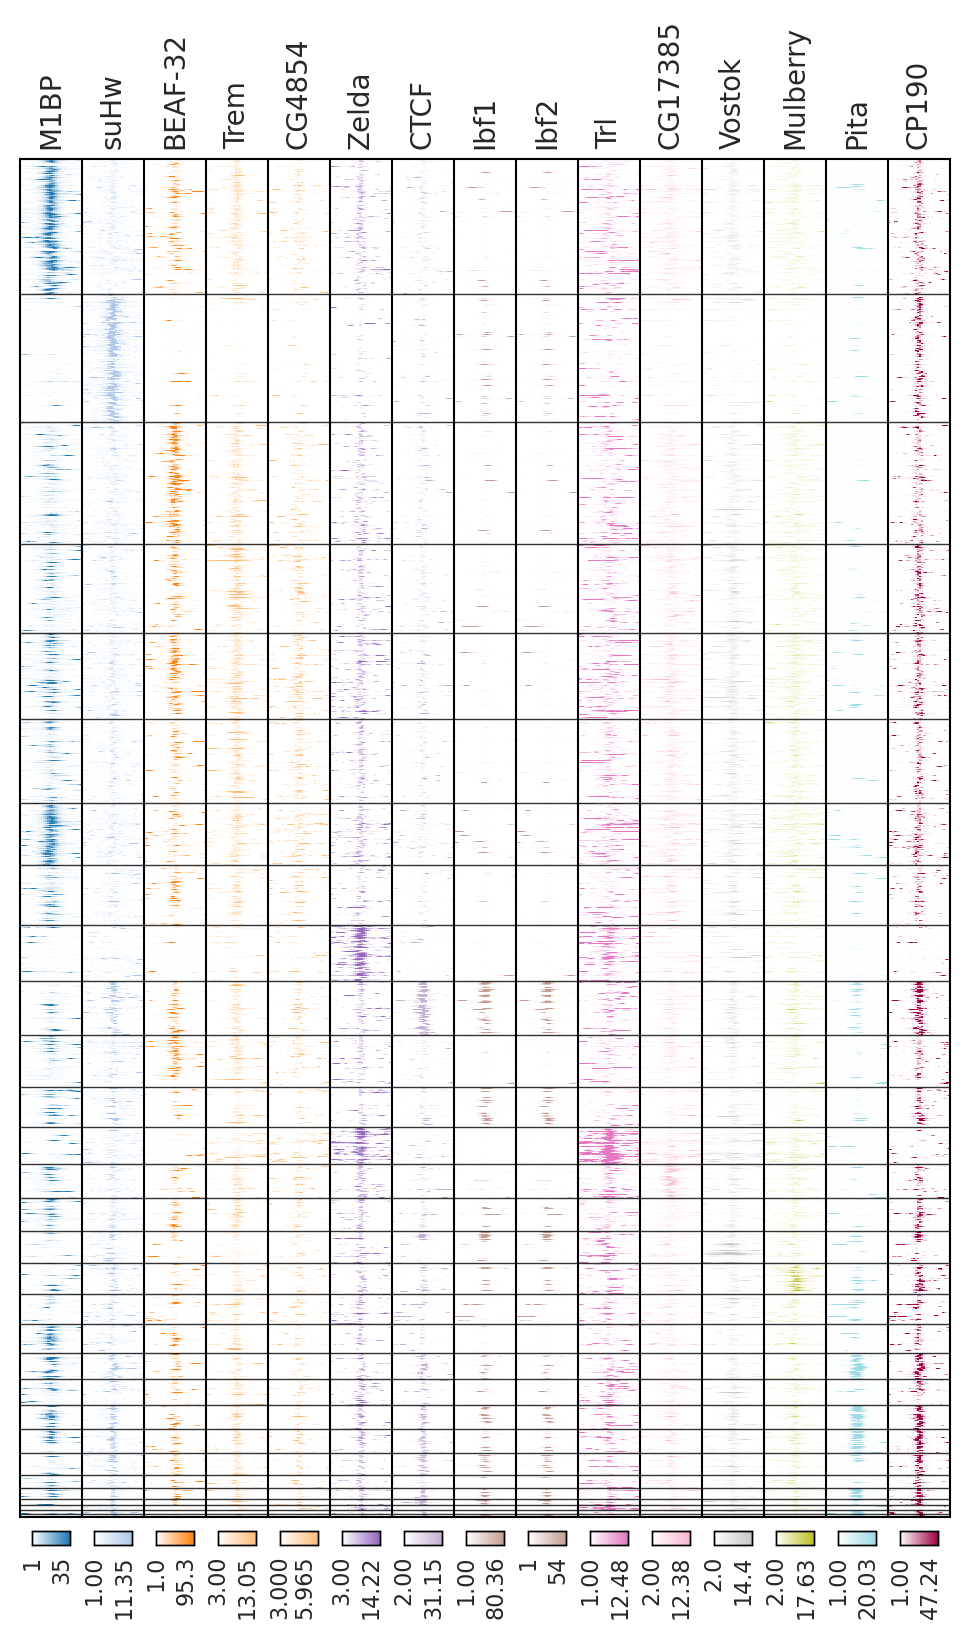

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.patches import Rectangle
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D


TARGET2FACTOR = {
    'zld': 'Zelda',
    'Trl': 'Trl',
    'pita':'Pita',
    'suHw': 'su(Hw)'
}

row_groups = sorted_labels.reset_index(drop=True)

K = 30
row_colors = pd.Series(colors_K[:K])
row_colors.index = np.arange(K)
ordered_groups = row_groups
boundaries = ordered_groups[ordered_groups != ordered_groups.shift(1)].index.tolist()


fig = plt.figure(figsize=(len(target2bbi) * 0.4, 9))

gs = GridSpec(2, len(target2bbi), height_ratios=[20, 0.2], wspace=0.0, hspace=0.02)

axes_heatmap = []
axes_cbar = []

for i, target in enumerate(target2bbi):
    arr = all_factor_arrs[i]
    
    # Heatmap axes
    ax_hm = fig.add_subplot(gs[0, i])
    
    cmap = histone_cmaps[target]
    vmax = arr.max() * 0.4
    vmin = 1
    if target == 'Trem' or target == 'CG4854':
        vmin = 3
        vmax = arr.max() * 0.4
    if target == "Zelda":
        vmin = 3
        vmax = arr.max() * 0.7
    if target == "CTCF":
        vmin = 2
        vmax = arr.max() * 0.4
    if target in ['Vostok', 'Mulberry']:
        vmin = 2
        vmax = arr.max() * 0.9
    if target == "CG17385":
        vmin = 2
        vmax = arr.max() * 0.8
    if 'Ibf' in target:
        vmin = 1
        vmax = arr.max() * 0.1
        
    sns.heatmap(arr, cmap=cmap, cbar=False, vmax = vmax, vmin=vmin, ax=ax_hm, rasterized=True)
    factor = target
    ax_hm.set_title(f'{factor}', fontsize=10, rotation=90)
    ax_hm.set_xticks([])  # Hide x ticks 
    ax_hm.set_yticks([])  # Hide x ticks 
    for b in boundaries[1:]:
        ax_hm.hlines(b - 0.5, *ax_hm.get_xlim(), colors='black', linewidth=0.5, alpha=0.8)
        
    axes_heatmap.append(ax_hm)
    
    ax_cb = fig.add_subplot(gs[1, i])
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=ax_cb, orientation="horizontal")
    cbar.set_ticks([vmin, vmax * 0.8])
    cbar.ax.tick_params(labelsize=8, width=0.25, length=1, rotation=90, direction='in')
    for spine in ax_cb.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor('black')
        spine.set_linewidth(0.5)
    # make colorbar thinner
    pos = ax_cb.get_position()
    ax_cb.set_position([pos.x0 + 0.01, pos.y0, pos.width - 0.02, pos.height])
        
    axes_cbar.append(cbar)

all_axes = axes_heatmap
positions = [ax.get_position() for ax in all_axes]
x0 = min(p.x0 for p in positions)
x1 = max(p.x1 for p in positions)
y0 = min(p.y0 for p in positions)
y1 = max(p.y1 for p in positions)

# Draw bounding box around full grid
bbox = Rectangle(
    (x0, y0),
    x1 - x0,
    y1 - y0,
    transform=fig.transFigure,
    linewidth=0.75,
    edgecolor='black',
    facecolor='none',
    zorder=100
)
fig.patches.append(bbox)

# Draw vertical lines between heatmaps
positions_top = axes_heatmap  # only top row
positions = [ax.get_position() for ax in positions_top]
line_xs = [(positions[i].x1 + positions[i+1].x0)/2 for i in range(len(positions)-1)]
y0 = min(p.y0 for p in positions)
y1 = max(p.y1 for p in positions)
for x in line_xs:
    line = Line2D([x, x], [y0, y1], transform=fig.transFigure, color='black', linewidth=0.75, zorder=200)
    fig.lines.append(line)

# plt.savefig("plots/tornado_plots_for_clustergram.pdf", dpi=300, bbox_inches='tight')

plt.show()


## Enrichment of ChIP-seq

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Cluster 1 vs. Cluster 7: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.201e-01 U_stat=4.081e+04
Cluster 7 vs. Other Clusters: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.318e-69 U_stat=6.261e+05
Cluster 1 vs. Other Clusters: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.642e-113 U_stat=1.306e+06
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Cluster 2 vs. Other Clusters: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:8.558e-131 U_stat=1.364e+06
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.0

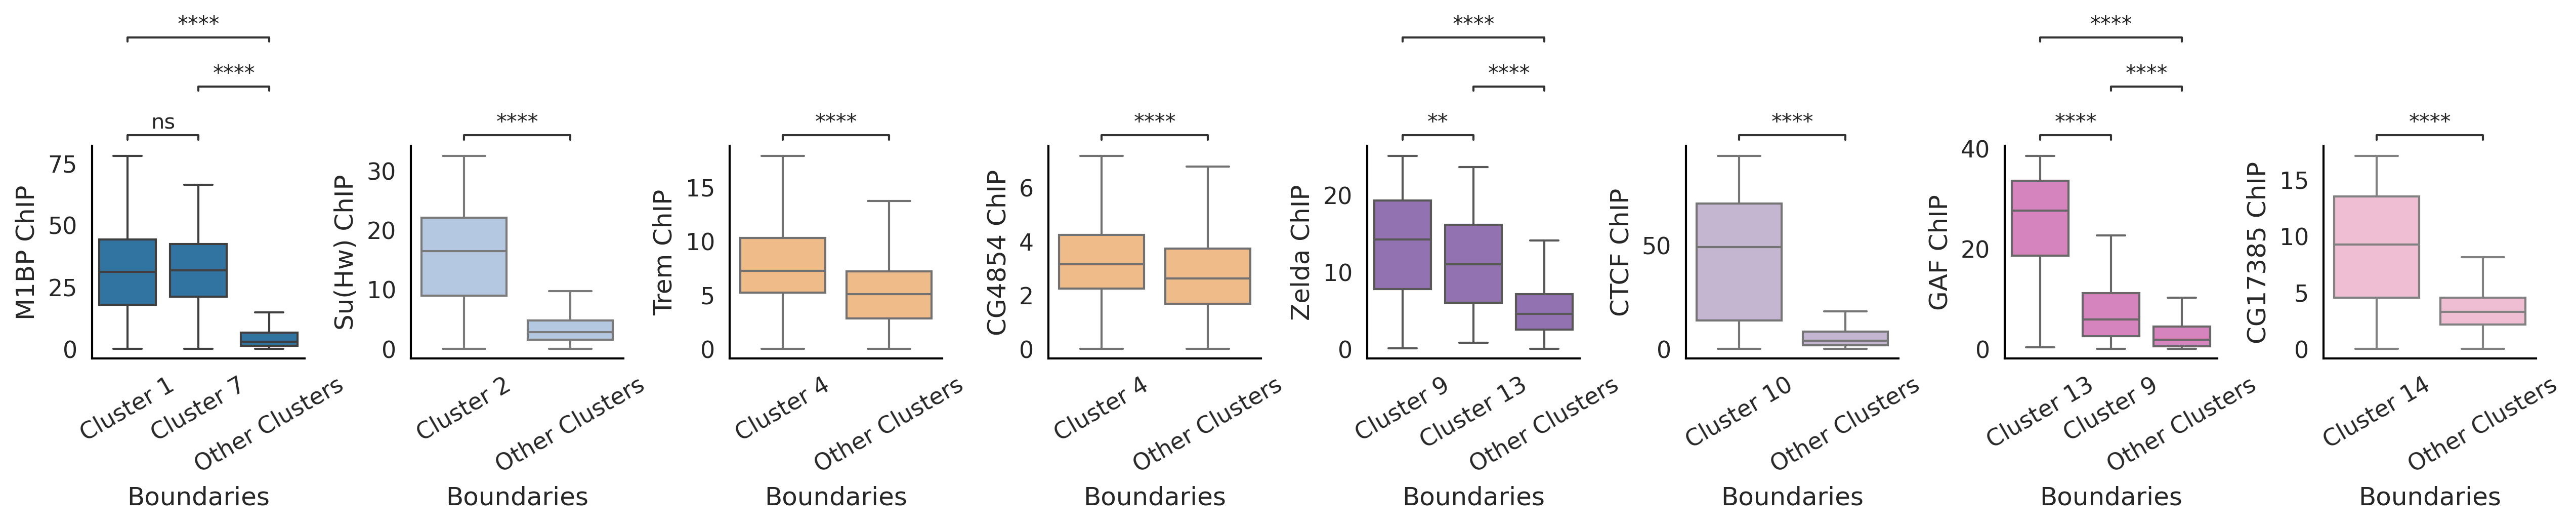

In [24]:
from statannotations.Annotator import Annotator
import itertools 

SELECT_CLUSTERS = [('M1BP', [0, 6]), ('Su(Hw)', [1]), ('Motif-8', [3]), ('Motif-8', [3]), ('Zelda', [8, 12]), ('CTCF', [9]),
                    ('GAGA', [12, 8]), ('AAG3', [13])]
SELECT_TARGETS = ['M1BP', 'suHw', 'Trem', 'CG4854', 'Zelda', 'CTCF', 'Trl', 'CG17385']

fig, axs = init_subplots_exact(len(SELECT_TARGETS),1,dpi=300, y_ratios=[0.35], x_ratios=[0.35] * len(SELECT_TARGETS), yspace=2, xspace=1.5)

counter = 0
for i, (target, (annotation, clusters)) in enumerate(zip(SELECT_TARGETS, SELECT_CLUSTERS)):
    ax = axs[i]
    plt.sca(ax)
    
    tmp_df = bdf_plot.copy()
        
    tmp_df[annotation] = target2bbi[target].stackup(tmp_df.chrom, tmp_df.start, tmp_df.end, bins=1)
    tmp_df['group'] = [f'Cluster {c + 1}' if c in clusters else f'Other Clusters' for c in tmp_df.cluster]
    
    # alphabetical order
    if target != 'Trl':
        my_order = sorted(tmp_df['group'].unique(), key=lambda x: (
            x == "Other Clusters",           # False before True
            int(x.split()[1]) if x != "Other Clusters" else float("inf")
        )) 
    else:
        my_order = sorted(tmp_df['group'].unique())

    bx = sns.boxplot(tmp_df, x='group', y=annotation, order=my_order,
                     showfliers=False, flierprops=dict(marker='o', color='black', markersize=0.5),
                     color=colors_K[clusters[0]], ax=ax)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.grid(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_linewidth(1)
        ax.spines[spine].set_color('black')


    column_pairs = list(itertools.combinations(my_order, 2))

    annot = Annotator(bx, column_pairs, data=tmp_df, x='group', y=annotation, order=my_order)
    annot.configure(test='Mann-Whitney', 
                    text_format='star', loc='outside', 
                    verbose=2, hide_non_significant=False, line_width=1, 
                    comparisons_correction='fdr_bh')
    annot.apply_test()
    bx, test_results = annot.annotate()

    if target == 'Trl':
        target = 'GAF'
    if target == 'suHw':
        target = 'Su(Hw)'
    ax.set_ylabel(f'{target} ChIP', fontsize=12)
    ax.set_xlabel(f'Boundaries', fontsize=12)
    ax.tick_params(axis='both', labelsize=11)
    plt.xticks(rotation=30)

# plt.savefig("plots/chip_seq_boxplots.pdf", dpi=300, bbox_inches='tight')
plt.show()


BEAF-32
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Cluster 3 vs. Other Clusters: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.612e-53 U_stat=1.109e+06
Ibf1
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Cluster 12 vs. Other Clusters: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.154e-19 U_stat=3.845e+05
Ibf2
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Cluster 12 vs. Other Clusters: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.317e-20 U_stat=3.870e

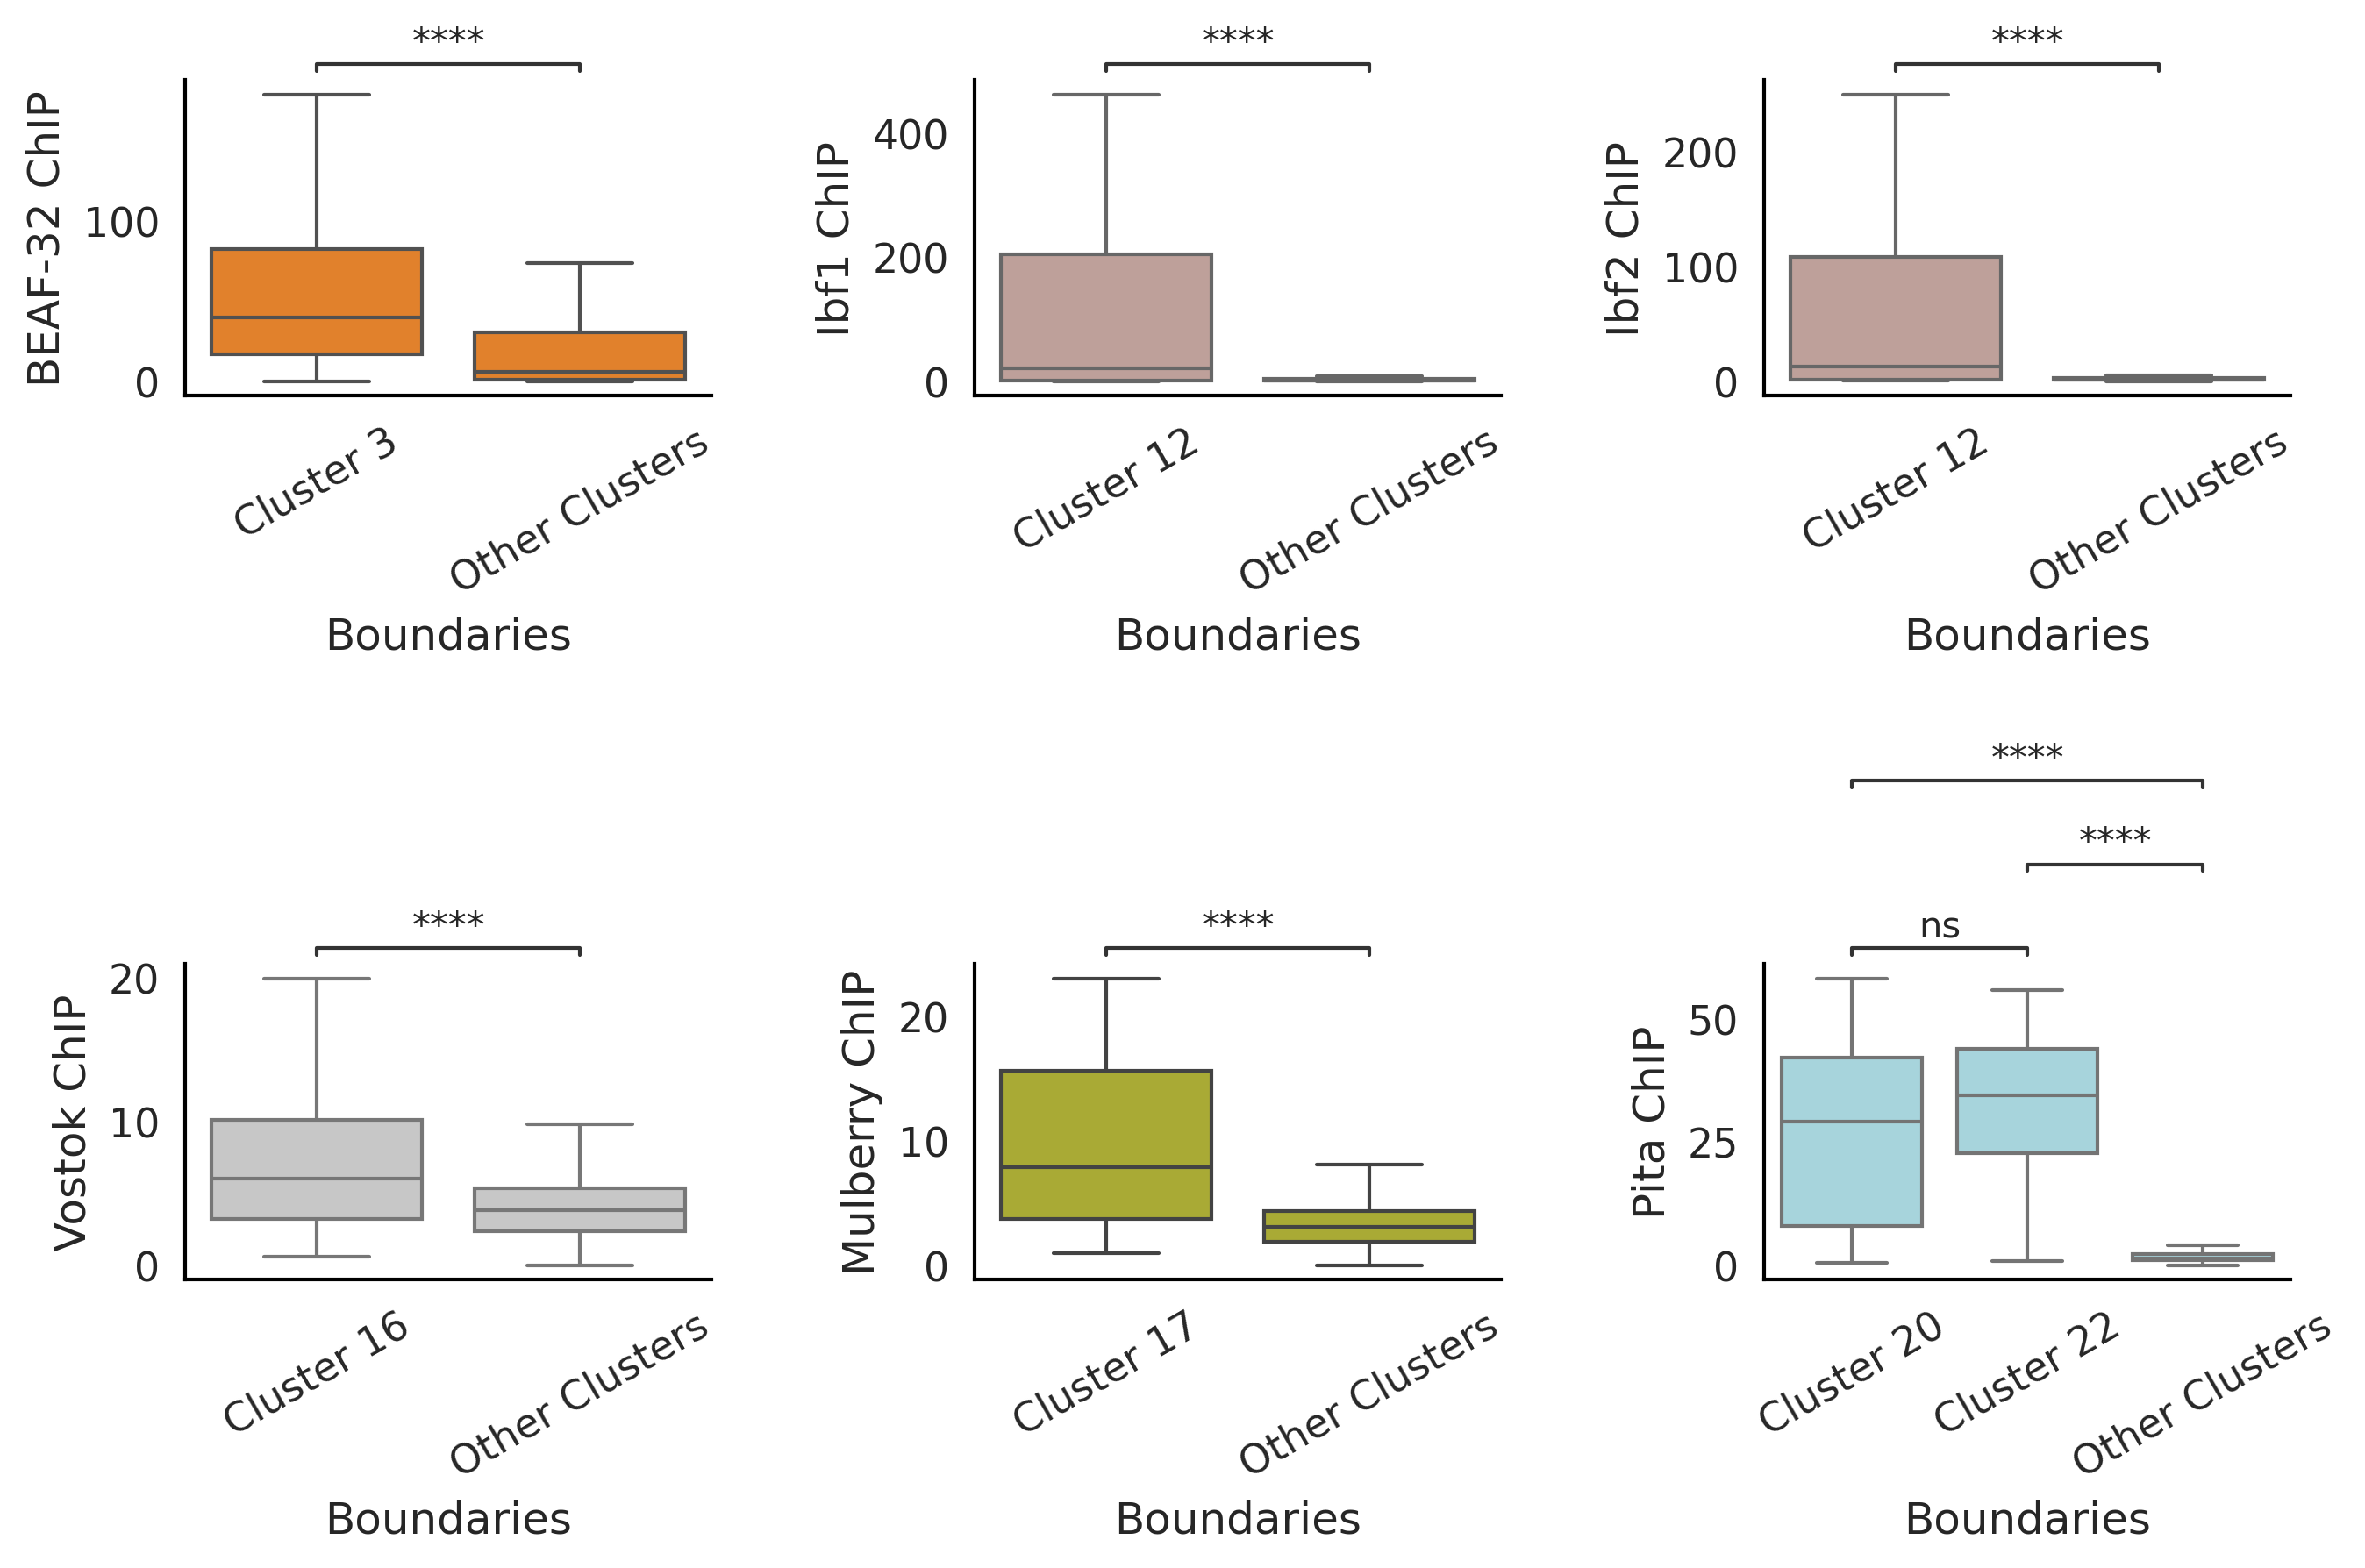

In [26]:
from statannotations.Annotator import Annotator
import itertools 

SELECT_CLUSTERS = [('BEAF-32', [2]), ('Ibf', [11]), ('Ibf', [11]),  ('Vostok', [15]), ('Mulberry', [16]), ('Pita', [19, 21])]
SELECT_TARGETS = ['BEAF-32', 'Ibf1', 'Ibf2', 'Vostok', 'Mulberry', 'Pita']

# fig, axs = init_subplots_exact(9,3,dpi=300, y_ratios=[0.3] * 3, x_ratios=[0.5] * 3, xspace=2, yspace=2)
fig, axs = init_subplots_exact(len(SELECT_TARGETS),2,dpi=300, y_ratios=[0.3] * 2, x_ratios=[0.5] * len(SELECT_TARGETS), yspace=2.8, xspace=1.5)

counter = 0
for i, (target, (annotation, clusters)) in enumerate(zip(SELECT_TARGETS, SELECT_CLUSTERS)):
    ax = axs[i]
    plt.sca(ax)
    # only those with < 3 instances
    tmp_df = bdf_plot.copy()

    tmp_df[annotation] = target2bbi[target].stackup(tmp_df.chrom, tmp_df.start, tmp_df.end, bins=1)
    tmp_df['group'] = [f'Cluster {c + 1}' if c in clusters else f'Other Clusters' for c in tmp_df.cluster]
    print(target)
    # alphabetical order
    my_order = sorted(tmp_df['group'].unique()) 

    bx = sns.boxplot(tmp_df, x='group', y=annotation, order=my_order,
                     showfliers=False, flierprops=dict(marker='o', color='black', markersize=0.5),
                     color=colors_K[clusters[0]], ax=ax)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.grid(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_linewidth(1)
        ax.spines[spine].set_color('black')


    column_pairs = list(itertools.combinations(my_order, 2))


    # add signifinance annotations
    annot = Annotator(bx, column_pairs, data=tmp_df, x='group', y=annotation, order=my_order)
    annot.configure(test='Mann-Whitney', 
                    text_format='star', loc='outside', 
                    verbose=2, hide_non_significant=False, line_width=1, line_offset=0.01, 
                    comparisons_correction='fdr_bh')
    annot.apply_test(alternative='greater')
    bx, test_results = annot.annotate()

    if target == 'Trl':
        target = 'GAF'
    # ax.set_title(annotation, fontsize=12, y=1.2)
    ax.set_ylabel(f'{target} ChIP', fontsize=12)
    ax.set_xlabel(f'Boundaries', fontsize=12)
    ax.tick_params(axis='both', labelsize=11)
    plt.xticks(rotation=30)
# plt.savefig("/scratch/gpfs/PRITYKIN/brendan/domino/figures/chip_seq_boxplots.pdf", dpi=300, bbox_inches='tight')
fig.show()


## Insulation across boundaries

In [27]:
def top_whisker(values):
    q1 = np.percentile(values, 25)
    q3 = np.percentile(values, 75)
    iqr = q3 - q1
    upper_fence = q3 + 1.5 * iqr
    return upper_fence


model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'

TRAIN_df = pd.read_csv(os.path.join(model_dir, 'TRAIN_df.csv'))
VAL_df = pd.read_csv(os.path.join(model_dir, 'VAL_df.csv'))
TEST_df = pd.read_csv(os.path.join(model_dir, 'TEST_df.csv'))

/tmp/ipykernel_3624397/1013008773.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(df, y='factor', x='frequency', ax=ax, palette=colors)


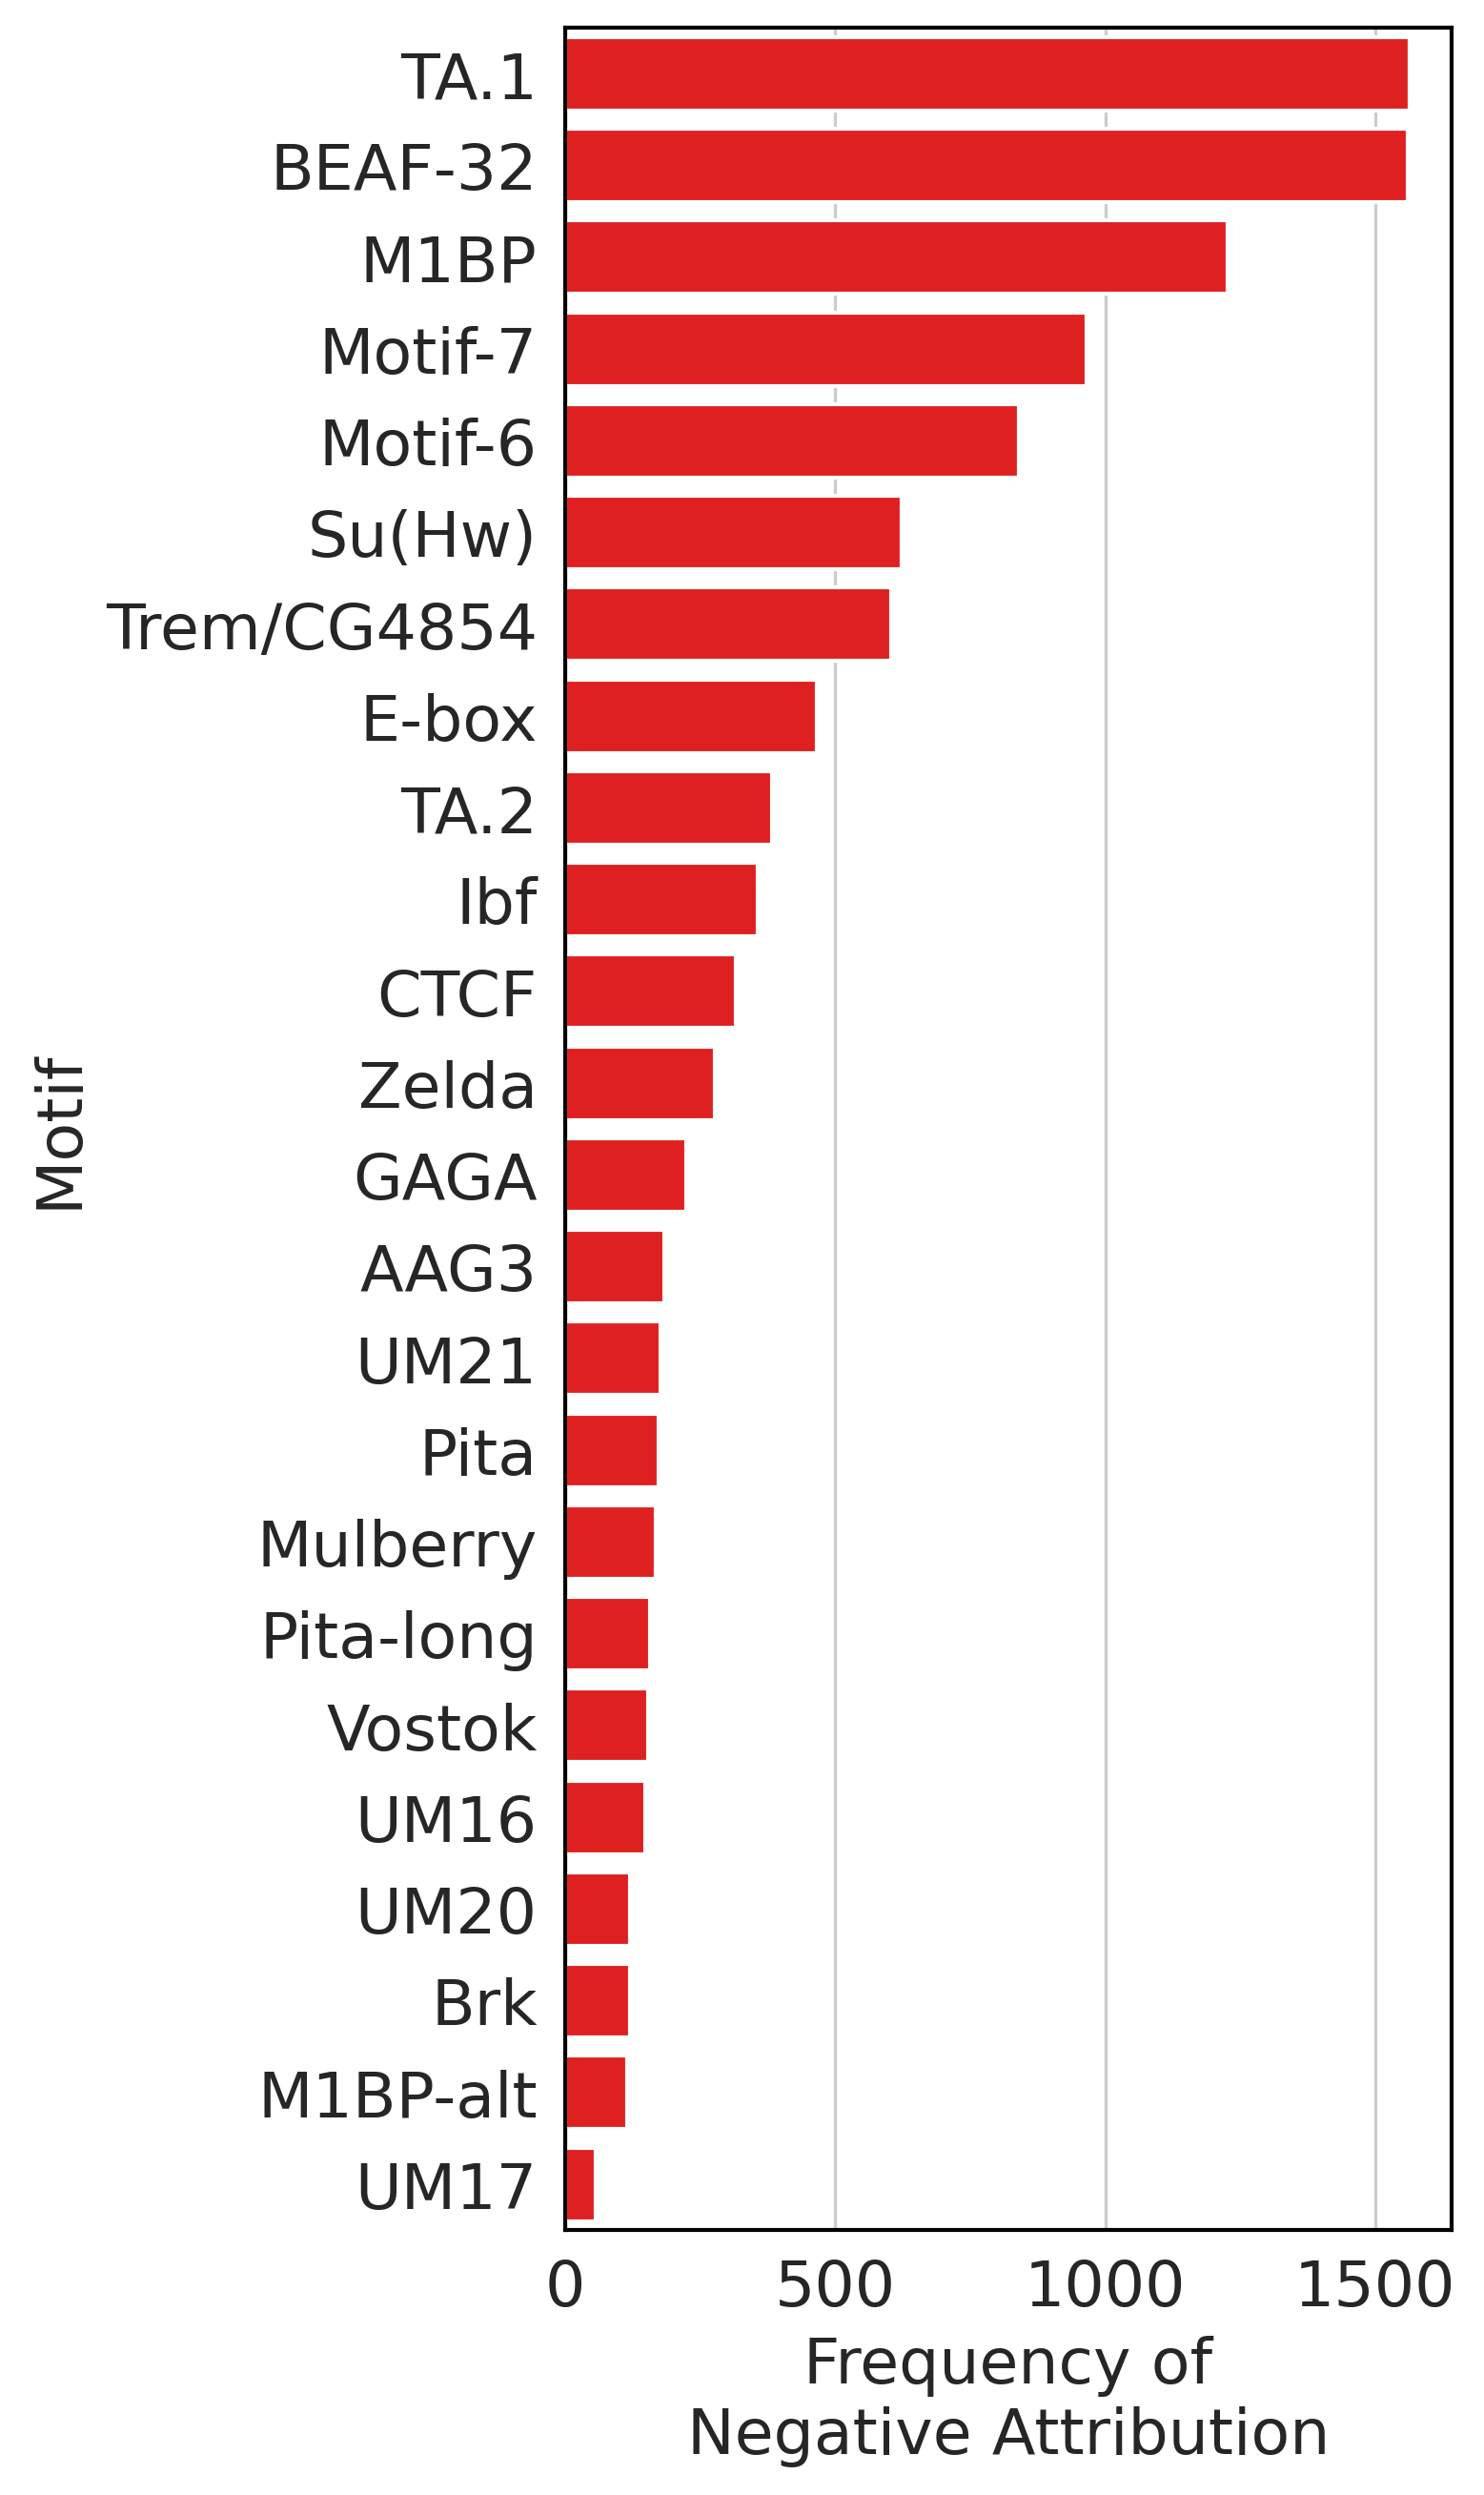

In [28]:
old_rc = plt.rcParams.copy()
plt.rcParams['font.size'] = 16

fig, ax = plt.subplots(1,1,dpi=300, figsize=(4, 10))

df = pd.DataFrame((active_rows_df < 0).sum(axis=0).sort_values(ascending=False), columns=['frequency'])
df['factor'] = [npatterns2targets[c][0] for c in df.copy().index.tolist()]

colors = ['red' if i < 26 else 'gray' for i in range(len(df))]
sns.barplot(df, y='factor', x='frequency', ax=ax, palette=colors)
plt.ylabel('Motif')
plt.xlabel('Frequency of\nNegative Attribution')
ax.tick_params(axis='y', labelsize=16)
for spine in ax.spines:  
    ax.spines[spine].set_color('black')  
    ax.spines[spine].set_linewidth(1)  # Decrease spine thickness
    
plt.show()

plt.rcParams.update(old_rc)

In [30]:
# For Figure 6 (Synergy)
# synergy_df = pd.DataFrame({
#     'pattern': df.iloc[:20].index,
#     'target': df.iloc[:20].factor
# }).reset_index(drop=True)
# synergy_df.to_csv('../fig6_synergy/top20_nc14_motifs_for_synergy.csv', index=False)


## Number of strong motif instances

In [30]:
# NUMBER OF STRONG MOTIF INSTANCES FOR EACH MOTIF PER BOUNDARY
# Number of motifs is the average of the motif count across both strands (rounded up)
counts_mat_final = pd.DataFrame(np.ceil(counts_mat_combined / 2), columns=final_patterns_df.pattern)
counts_mat_final = counts_mat_final.loc[clustergram_sorted_matrix.index, active_rows_df_sorted.columns]
counts_mat_final = counts_mat_final[(clustergram_sorted_matrix < GLOBAL_CUTOFF).columns]
counts_mat_final = counts_mat_final * (clustergram_sorted_matrix < GLOBAL_CUTOFF)
counts_mat_final.columns = [npatterns2targets[p][0] for p in counts_mat_final.copy().columns]
counts_mat_final = counts_mat_final[[npatterns2targets[col][0] for col in column_order]]

strong_boolean_df = clustergram_sorted_matrix.copy() < GLOBAL_CUTOFF
bdf_plot['num_strong_motif_classes'] = strong_boolean_df.sum(axis=1)

In [31]:
bdf_plot['num_strong_motif_classes'].mean()

2.031009559337841

In [32]:
bdf_plot.num_strong_motif_classes.value_counts(normalize=True)

num_strong_motif_classes
1    0.411984
2    0.296573
3    0.179063
4    0.081371
5    0.024015
6    0.005829
7    0.001166
Name: proportion, dtype: float64

/tmp/ipykernel_3624397/1454555690.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='num_strong', y='proportion', data=frequency_df, ax=ax, palette=colors)
/tmp/ipykernel_3624397/1454555690.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x='category', y='demeaned_ins_score_1', data=plt_df, showfliers=False,


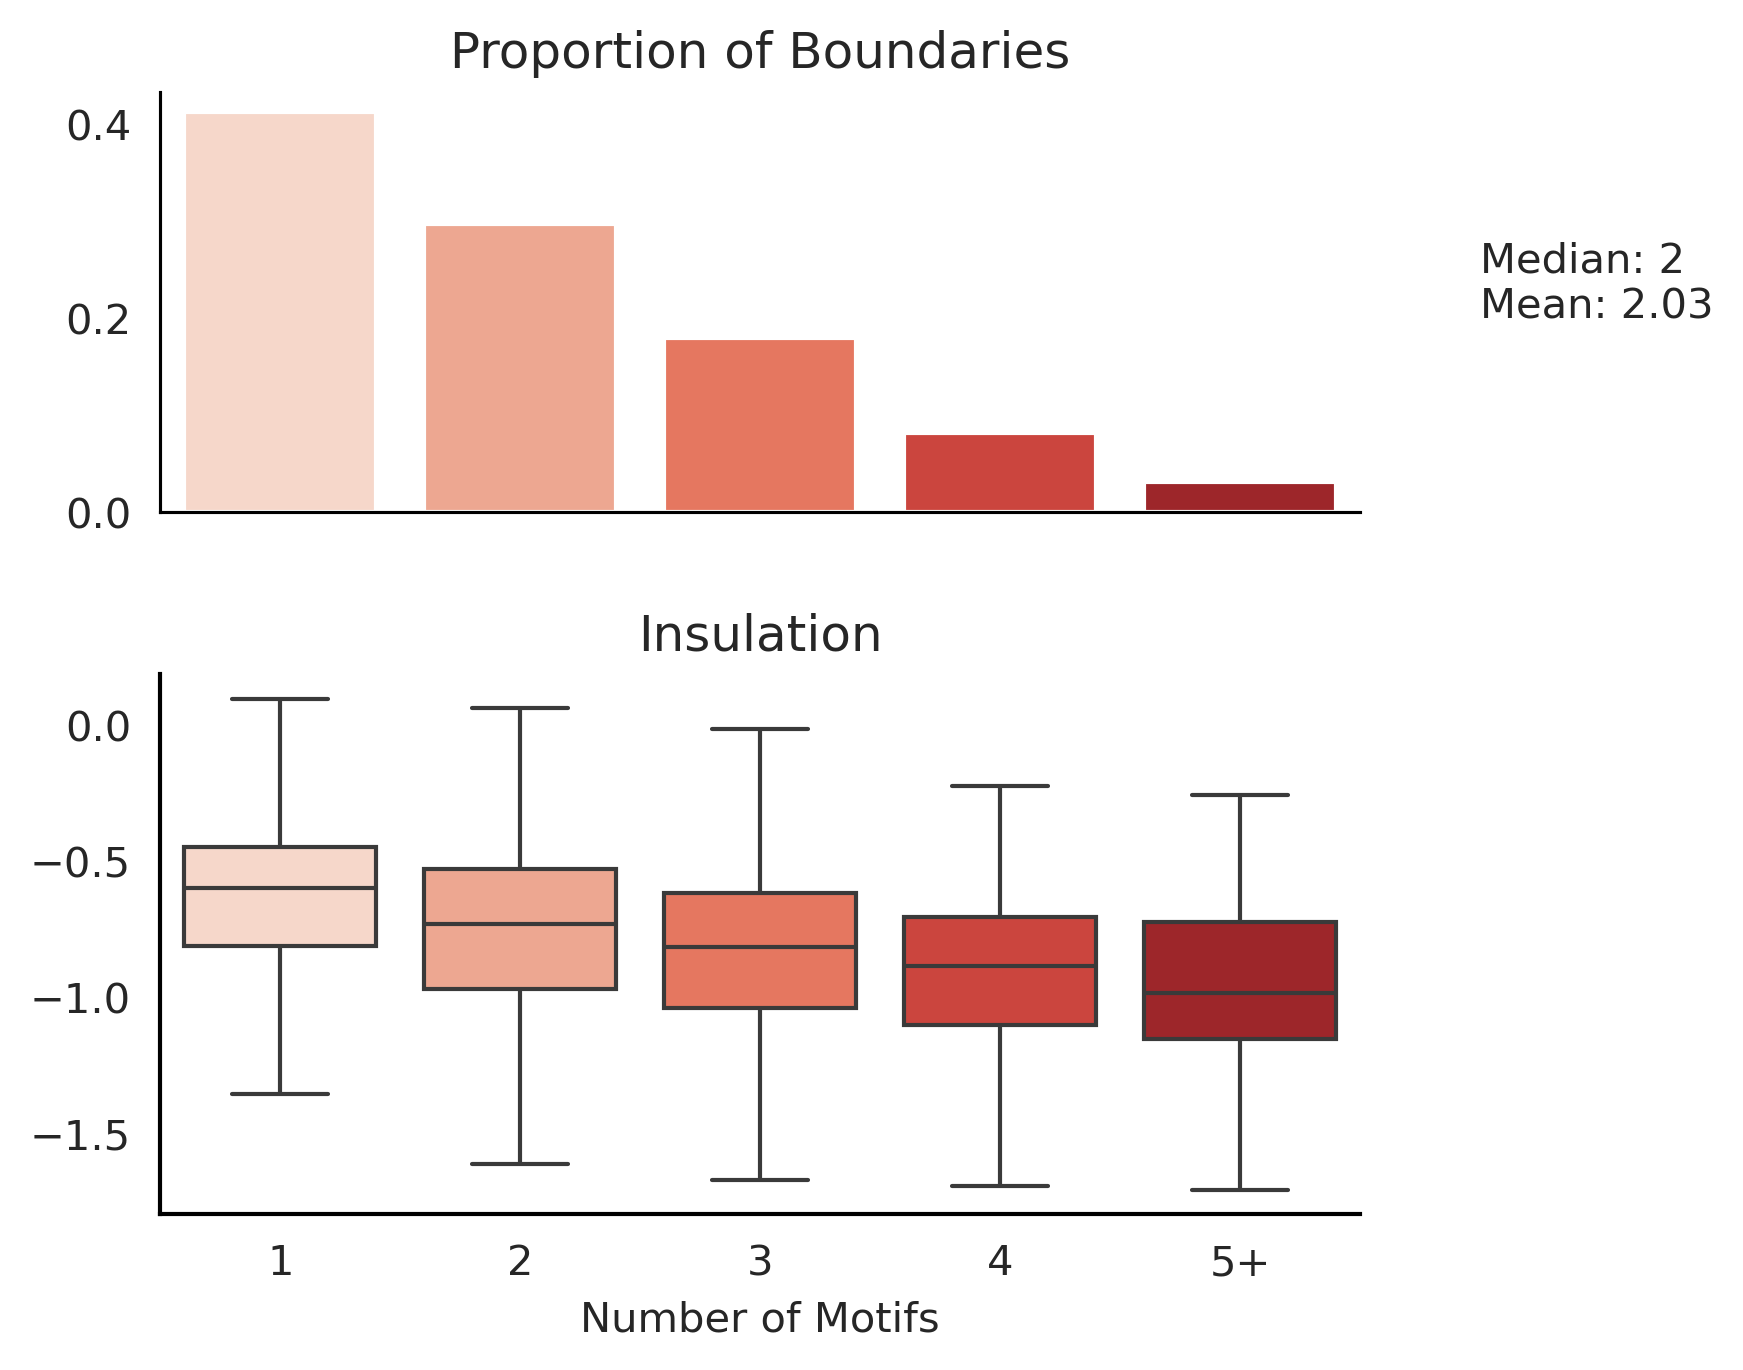

In [33]:

frequency_series = (
    bdf_plot['num_strong_motif_classes'].clip(upper=5)          # 5,6,7,... -> 5
     .replace(5, '5+')       # 5 -> '5+'
     .value_counts(normalize=True)
     .reindex([1, 2, 3, 4, '5+'], fill_value=0)
)

frequency_df = pd.DataFrame({
    'num_strong': frequency_series.index,
    'proportion': frequency_series
})


fig, axs = init_subplots_exact(2,2, dpi=300, y_ratios=[0.35, 0.45], x_ratios=[1], yspace=1.3)

plt.sca(axs[0])
ax=axs[0]

colors = sns.color_palette("Reds", n_colors=len(frequency_df.num_strong.unique()))
sns.barplot(x='num_strong', y='proportion', data=frequency_df, ax=ax, palette=colors)

plt.grid(False)
plt.text(5, 0.2, f"Median: {bdf_plot['num_strong_motif_classes'].median():.0f}\nMean: {bdf_plot['num_strong_motif_classes'].mean():.2f}")
plt.title("Proportion of Boundaries")
plt.xlabel('')
plt.ylabel('')

plt.xticks([])
plt.yticks([0, 0.2, 0.4])

ax.tick_params(axis='both')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

for spine in ['bottom', 'left']:
    ax.spines[spine].set_linewidth(0.75)
    ax.spines[spine].set_color('black')
    
plt.sca(axs[1])
ax=axs[1]

plt_df = bdf_plot.copy()
plt_df["category"] = pd.Categorical(
    np.where(plt_df["num_strong_motif_classes"].astype(int) >= 5, "5+", plt_df["num_strong_motif_classes"].astype(str)),
    categories=["1", "2", "3", "4", "5+"],
    ordered=True,
)

colors = sns.color_palette("Reds", n_colors=len(plt_df.category.unique()))
ax = sns.boxplot(x='category', y='demeaned_ins_score_1', data=plt_df, showfliers=False, 
                 flierprops=dict(marker='o', color='black', markersize=1),
                palette=colors)

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.grid(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_linewidth(1)
    ax.spines[spine].set_color('black')
    

plt.title('Insulation')
plt.ylabel('')
plt.xlabel('Number of Motifs')

# plt.savefig("plots/insulation_against_num_strong_motifs.pdf", dpi=300, bbox_inches='tight')
plt.show()



## General co-activity

In [34]:
import scipy 
from statsmodels.stats.multitest import multipletests

print('nonzero rows df', nonzero_rows_df.shape)
print('active rows df', active_rows_df.shape) # all rows with at least one strong motif that fires

is_boundary_active_df = negative_rows_df < GLOBAL_CUTOFF

print('is_boundary_active_df', is_boundary_active_df.shape) # indicator matrix across all neg boundaries on whether it contains at least one boundary

results = []
for col in is_boundary_active_df:
    has_active_motif = (is_boundary_active_df[col] > 0)
    has_no_other_active_motif = (is_boundary_active_df.drop(col, axis=1) == 0).all(axis=1) 
    odds, p = scipy.stats.fisher_exact([
        [(has_active_motif & has_no_other_active_motif).sum(), (has_active_motif & ~has_no_other_active_motif).sum()],
        [(~has_active_motif & has_no_other_active_motif).sum(), (~has_active_motif & ~has_no_other_active_motif).sum()]
    ])
    num_only_active_motif = (has_active_motif & has_no_other_active_motif).sum()
    num_active_motif = len(is_boundary_active_df[is_boundary_active_df[col] > 0])
    
    fraction = num_only_active_motif / num_active_motif    
    results.append([fraction, num_only_active_motif, num_active_motif, col, odds, p])
results = pd.DataFrame(results, columns = ['fraction_lone_wolf', 'num_only_active_motif', 'num_active_motif', 'motif_name', 'odds', 'p'])
results = results.set_index('motif_name')
results['idx'] = np.arange(len(results))

ALPHA = 5e-2
_, pvals_corrected, _, _ = multipletests(results['p'], alpha=ALPHA, method='fdr_bh')
results['bh_corrected_p'] = pvals_corrected
results['significance'] = -np.log10(results['bh_corrected_p'])
results['motif'] = [npatterns2targets[p] for p in results.index]

nonzero rows df (4778, 24)
active rows df (4289, 24)
is_boundary_active_df (4766, 24)


/tmp/ipykernel_3624397/559080288.py:22: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ax.annotate(npatterns2targets[labels[i]][0], (x[i], y[i]),
/tmp/ipykernel_3624397/559080288.py:29: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if results.iloc[i].fraction_lone_wolf > FRAC_UB: plt.scatter(x[i], y[i], s=30, alpha=0.5, color='red')
/tmp/ipykernel_3624397/559080288.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if results.iloc[

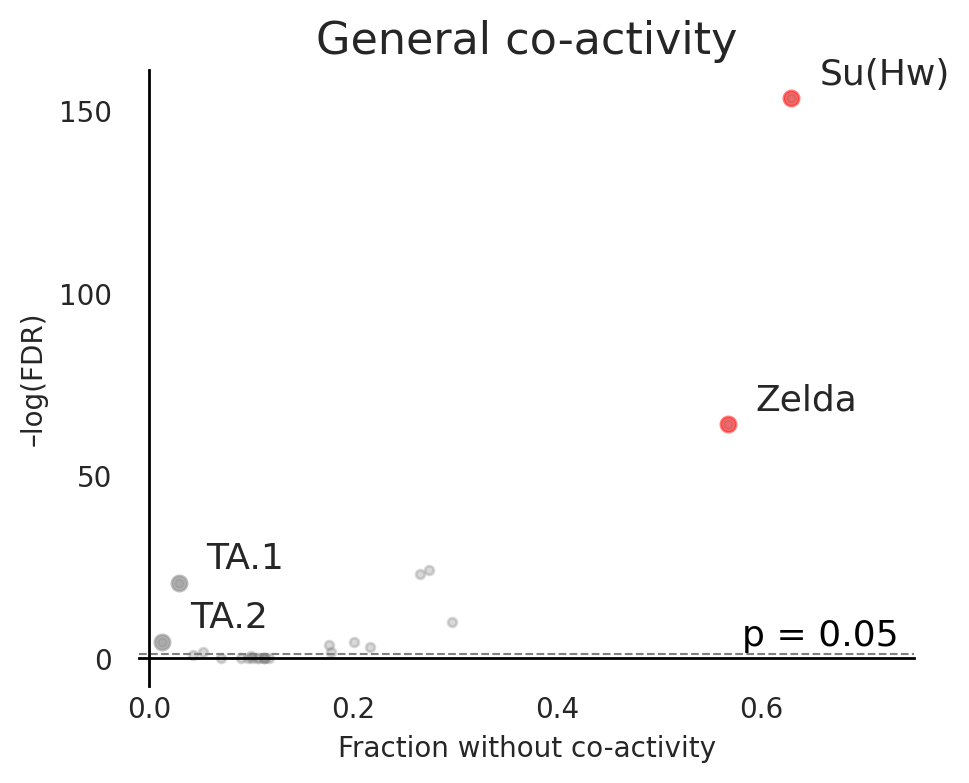

In [35]:
# old_rc = plt.rcParams.copy()
# plt.rcParams['font.size'] = 16

fig, ax = plt.subplots(1, 1, figsize=(5, 4))
x, y = results['fraction_lone_wolf'], results['significance']

plt.scatter(x, y, s=10, alpha=0.3, color='gray')
plt.axhline(-np.log10(ALPHA), linewidth=0.75, color='gray', linestyle='dashed')
ax.text(x=0.98, y=-np.log10(ALPHA)*1.1, s=f'p = {ALPHA}', color='black',
        ha='right', va='bottom', fontsize=13,
        transform=ax.get_yaxis_transform())

ax.grid(False)
ax.spines[['right', 'top']].set_visible(False)

# annotate_indices = results.query('significance > @sig_cutoff').idx
ALPHA = 5e-2
FRAC_LB, FRAC_UB = 0.03, 0.35
annotate_indices = results.query('bh_corrected_p < @ALPHA and (fraction_lone_wolf > 0.35 or fraction_lone_wolf < 0.03)').idx
labels = results.index
for i in annotate_indices:
    ax.annotate(npatterns2targets[labels[i]][0], (x[i], y[i]),
                textcoords="offset points",  # Position relative to point
                xytext=(10, 5),              # Offset of the label
                ha='left',
                fontsize=13,
    )
    if results.iloc[i].bh_corrected_p < ALPHA:
        if results.iloc[i].fraction_lone_wolf > FRAC_UB: plt.scatter(x[i], y[i], s=30, alpha=0.5, color='red')
        if results.iloc[i].fraction_lone_wolf < FRAC_LB: plt.scatter(x[i], y[i], s=30, alpha=0.5, color='gray')


for spine in ['left', 'bottom']:  
    ax.spines[spine].set_color('black')  
    ax.spines[spine].set_linewidth(1)  # Decrease spine thickness
    ax.spines[spine].set_position('zero')

ax.tick_params(axis='x', direction='out', pad=10)
ax.tick_params(axis='y', direction='out', pad=10)

ax.set_xlim([-0.01, 0.75])

plt.xlabel('Fraction without co-activity')
plt.ylabel('–log(FDR)')
plt.title('General co-activity', fontsize=16)
plt.yticks([0, 50, 100, 150])
plt.xticks([0, 0.2, 0.4, 0.6])

# plt.savefig("plots/general_coactivity.pdf", dpi=300, bbox_inches='tight')

plt.show()

# plt.rcParams.update(old_rc)

Su(Hw)
1.0    328
2.0     33
3.0      1
Name: count, dtype: int64


/tmp/ipykernel_3624397/187876206.py:15: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  cluster_only = cluster_only[(counts_matrix_bool[target] == True) & (counts_matrix_bool.drop(columns=target).sum(axis=1) == 0)]


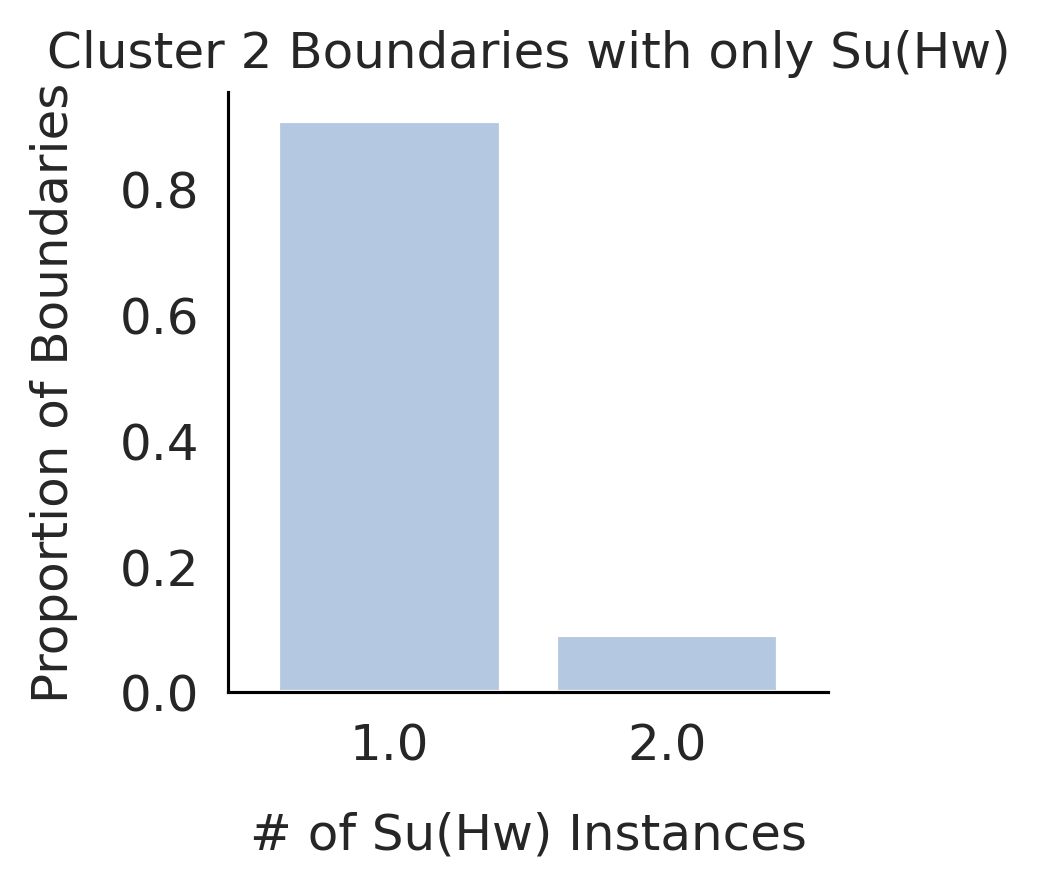

In [36]:

active_counts_matrix = counts_mat_final.copy()
bdf_plot_copy = bdf_plot.copy()
counts_matrix_bool = active_counts_matrix > 0

lone_wolf_dict = {
    1: 'Su(Hw)',
}

lone_wolf_only_clusters = dict()

fig, ax = init_subplots_exact(1,1,dpi=300, y_ratios=[0.5], x_ratios=[0.5])
for i, (cluster, target) in enumerate(lone_wolf_dict.items()):
    # get rows where ONLY the LW is present
    cluster_only = active_counts_matrix.loc[bdf_plot_copy.query('cluster == @cluster').index]
    cluster_only = cluster_only[(counts_matrix_bool[target] == True) & (counts_matrix_bool.drop(columns=target).sum(axis=1) == 0)]
    
    frequency_series = cluster_only[target][cluster_only[target] != 3.0].value_counts(normalize=True) 

    print(cluster_only[target].value_counts())

    frequency_df = pd.DataFrame({
        'num_active_instances': frequency_series.index,
        'proportion': frequency_series
    })

    lone_wolf_only_clusters[cluster] = pd.DataFrame(cluster_only[target])

    sns.barplot(x='num_active_instances', y='proportion', data=frequency_df, ax=ax, color=colors_K[cluster])
    ax.grid(False)
    ax.set_ylabel("Proportion of Boundaries", fontsize=12, labelpad=10)
    ax.set_xlabel(f"# of {target} Instances", fontsize=12, labelpad=10)
    ax.tick_params(axis='both', labelsize=12)
    ax.set_title(f'Cluster {cluster + 1} Boundaries with only {target}')

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    for spine in ['bottom', 'left']:
        ax.spines[spine].set_linewidth(0.75)
        ax.spines[spine].set_color('black')


    ax.margins(x=0.1)  # 10% padding on both axes
plt.subplots_adjust(top=0.95)
# plt.savefig("plots/cluster2_number_of_motif_instances.pdf", dpi=300, bbox_inches='tight')
plt.show()

Su(Hw)
1.0    328
2.0     33
Name: count, dtype: int64
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

1.0 vs. 2.0: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.161e-05 U_stat=2.906e+03


/tmp/ipykernel_3624397/1875056710.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lw_only_df['CP190'] = bdf_plot.loc[lw_only_df.index].CP190
/tmp/ipykernel_3624397/1875056710.py:33: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


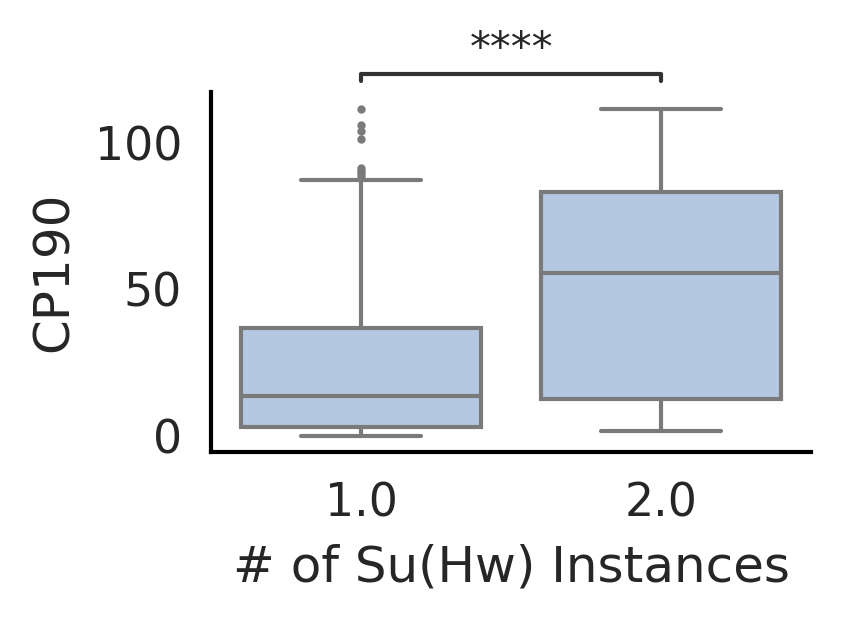

In [37]:
from statannotations.Annotator import Annotator
import itertools 

fig, ax = init_subplots_exact(1,1,dpi=300, y_ratios=[0.3], x_ratios=[0.5])
for i, (cluster, lw_only_df) in enumerate(lone_wolf_only_clusters.items()):

    # only those with < 3 instances
    lw_only_df = lw_only_df[lw_only_df['Su(Hw)'] < 3]
    
    target = lone_wolf_dict[cluster]
    lw_only_df['CP190'] = bdf_plot.loc[lw_only_df.index].CP190
    print(lw_only_df[target].value_counts())
    bx = sns.boxplot(lw_only_df, x=target, y='CP190', 
                     showfliers=True, flierprops=dict(marker='o', color='black', markersize=1),
                    color=colors_K[cluster], ax=ax)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.grid(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_linewidth(1)
        ax.spines[spine].set_color('black')
    
    # add signifinance annotations
    column_pairs = list(itertools.combinations(lw_only_df[target].unique(), 2))
    annot = Annotator(bx, column_pairs, data=lw_only_df, x=target, y='CP190')
    annot.configure(test='Mann-Whitney', text_format='star', loc='outside', verbose=2, hide_non_significant=False, line_width=1, comparisons_correction='fdr_bh')
    annot.apply_test()
    bx, test_results = annot.annotate()
    
    ax.set_ylabel('CP190', fontsize=12)
    ax.set_xlabel(f'# of {target} Instances', fontsize=12)
    ax.tick_params(axis='both', labelsize=11)
plt.tight_layout()
# plt.savefig("plots/cp190_across_categories.pdf", dpi=300, bbox_inches='tight')
plt.show()


## Pairwise co-activity

In [38]:
import itertools
import scipy
active_rows_boolean_df = negative_rows_df < GLOBAL_CUTOFF

column_pairs = list(itertools.combinations(active_rows_boolean_df.columns, 2))

results = []
for col1, col2 in column_pairs:
    
    has_active_motif1 = (active_rows_boolean_df[col1] > 0)
    has_active_motif2 = (active_rows_boolean_df[col2] > 0)
    no_active_motif1 = ~has_active_motif1
    no_active_motif2 = ~has_active_motif2
    odds, p = scipy.stats.fisher_exact([
        [(has_active_motif1 & has_active_motif2).sum(), (has_active_motif1 & no_active_motif2).sum()],
        [(no_active_motif1 & has_active_motif2).sum(), (no_active_motif1 & no_active_motif2).sum()]
    ], alternative='greater')
    fraction = (has_active_motif1 & has_active_motif2).mean()
    results.append([fraction, npatterns2targets[col1][0], npatterns2targets[col2][0], odds, p])

results = pd.DataFrame(results, columns = ['fraction_co_activate', 'motif_name1',
                                           'motif_name2', 'odds', 'p'])
results['log_odds'] = np.log10(results['odds'])
results['idx'] = np.arange(len(results))

ALPHA = 5e-2
_, pvals_corrected, _, _ = multipletests(results['p'], alpha=ALPHA, method='fdr_bh')
results['bh_corrected_p'] = pvals_corrected
results['significance'] = -np.log10(results['bh_corrected_p'])

/home/byw2/micromamba/envs/domino_vis/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


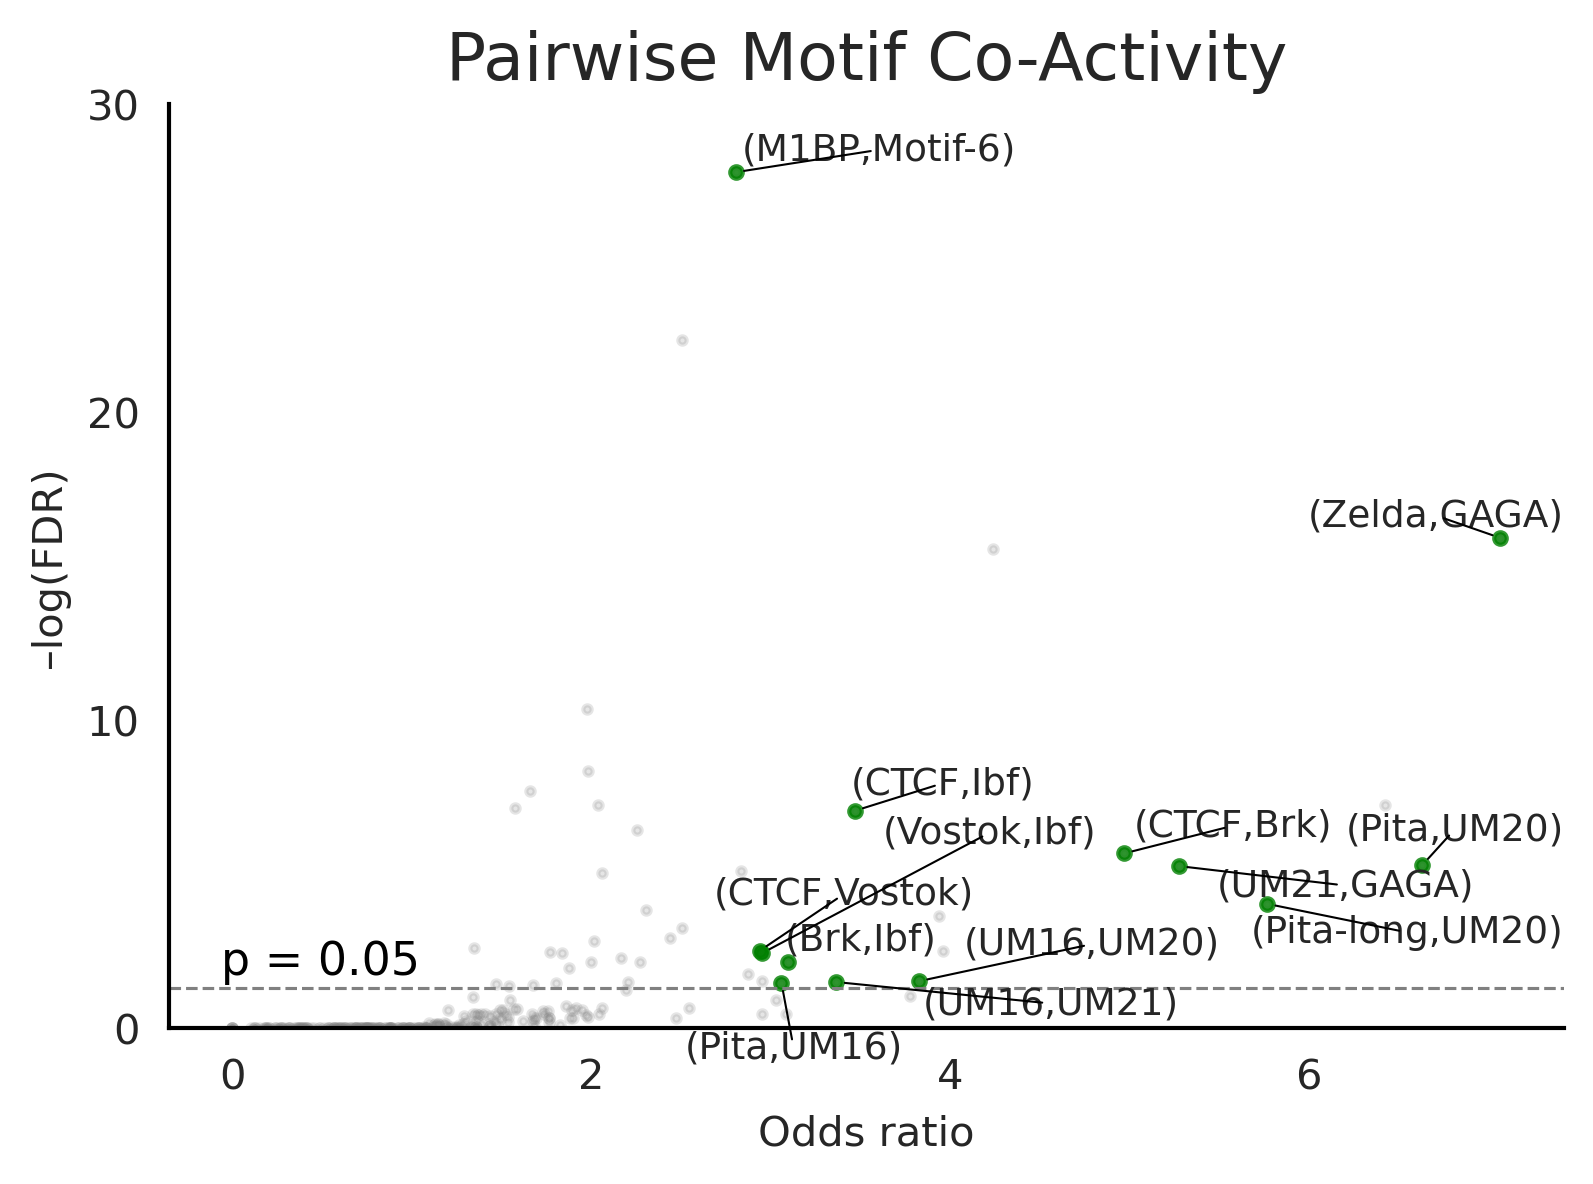

In [39]:
from adjustText import adjust_text

OR_CUTOFF = 2.5


fig, ax = plt.subplots(1, 1, figsize=(6,4), dpi=300)
x, y = results['odds'], results['significance']

plt.scatter(x, y, s=4, alpha=0.2, color='gray')
plt.xlabel('Odds ratio')
# plt.axvline(1, linewidth=0.75, color='gray', linestyle='dashed')
plt.axhline(0, linewidth=0.75, color='gray', linestyle='solid')
# plt.axvline(OR_CUTOFF, linewidth=0.5, color='gray', linestyle='dashed')
plt.axhline(-np.log10(ALPHA), linewidth=0.75, color='gray', linestyle='dashed')
plt.ylabel(f"–log(FDR)")
plt.title('Pairwise Motif Co-Activity', fontsize=16)
ax.grid(False)
ax.spines[['right', 'top']].set_visible(False)
ax.text(x=0.18, y=-np.log10(ALPHA)*1.1, s=f'p = {ALPHA}', color='black',
        ha='right', va='bottom', fontsize=11,
        transform=ax.get_yaxis_transform())

annotate_indices = results.query('bh_corrected_p < 0.05 and odds > @OR_CUTOFF and ~motif_name1.str.contains("TA") and ~motif_name2.str.contains("TA") and index != 105').idx
# AT_indices = results.query('bh_corrected_p < 0.05 and odds > 1 and motif_name1.str.contains("TA") or motif_name2.str.contains("TA")').idx
# annotate_indices = results.query('bh_corrected_p < 0.05 and odds > 2').idx

labels = [f'({i},{j})' for i,j in zip(results.motif_name1, results.motif_name2)]
texts = []
for i in annotate_indices:
    xi, yi = x[i], y[i]
    text = ax.text(xi, yi, labels[i], fontsize=9, zorder=3)
    texts.append(text)
    plt.scatter(x[i], y[i], s=9, alpha=0.8, color='green')

adjust_text(
    texts,
    x=x, y=y,
    ax=ax,
    force_text=(2, 2),
    force_points=(5, 5),
    explode_radius=100,
    lim=1000,
    arrowprops=dict(
        arrowstyle="-",
        color="black",
        lw=0.5,
    ),
)

for spine in ['left', 'bottom']:  
    ax.spines[spine].set_color('black')  
    ax.spines[spine].set_linewidth(1)  # Decrease spine thickness

ax.set_ylim([0, 30])
plt.yticks([0,10,20,30])
plt.xticks([0,2,4,6])

# plt.savefig("plots/pairwise_coactivity.pdf", dpi=300, bbox_inches='tight')

plt.show()

In [44]:
%matplotlib inline
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def plot_column(col, cbar_title, annotate=True, **kwargs):
    fig, ax = plt.subplots(figsize=(12, 10), dpi=300)
    
    motifs = sorted(set(results["motif_name1"]).union(results["motif_name2"]))
    
    mat = pd.DataFrame(np.nan, index=motifs, columns=motifs)
    p_mat = pd.DataFrame(np.nan, index=motifs, columns=motifs)

    # Fill the upper triangle
    for _, row in results.iterrows():
        g1, g2 = row["motif_name1"], row["motif_name2"]
        if g1 != g2:
            if g1 < g2:
                mat.loc[g2, g1] = row[col]
                p_mat.loc[g2, g1] = row['bh_corrected_p']
            else:
                mat.loc[g1, g2] = row[col]
                p_mat.loc[g1, g2] = row['bh_corrected_p']
                
        
    # Create mask for lower triangle + diagonal
    mask = np.triu(np.ones_like(mat, dtype=bool)) | np.isneginf(mat)

    if annotate:
        annot = np.full(mat.shape, "", dtype=object)
        annot[p_mat < 0.05] = "*"
        annot[p_mat < 0.01] = "**"
        annot[p_mat < 0.001] = "***"
        annot[p_mat < 1e-4] = "****"
    else:
        annot=None

    pos = ax.get_position()
    cbar_height = 0.03
    cbar_ax = fig.add_axes([
        pos.x0 * (1.4),              # left aligned with heatmap
        pos.y0 - 0.15,       # a little below heatmap
        pos.width * 0.8,           # EXACT same width
        cbar_height
    ])
    
    plt.grid(False)
    sns.heatmap(mat, mask=mask, square=True, fmt='s', annot=annot, 
                annot_kws={"ha": "center", "va": "center", "fontsize": 10},
                ax=ax, cbar_ax=cbar_ax, 
                cbar_kws={"orientation": "horizontal", "label": cbar_title},
                **kwargs)
    

    legend_elements = [
        Line2D([0], [0], color='w', marker=None, label='*  <0.05'),
        Line2D([0], [0], color='w', marker=None, label='**  <0.01'),
        Line2D([0], [0], color='w', marker=None, label='***  <0.001'),
        Line2D([0], [0], color='w', marker=None, label='****  <1e-4'),
    ]

    ax.legend(handles=legend_elements, loc='upper right', title="Significance")
    leg = ax.legend(
        handles=legend_elements,
        loc='upper right',
        title="Significance",
        frameon=True,        # show box
        edgecolor='black',   # black border
        handlelength=0,      # no line/marker
        handletextpad=0.5,
        labelspacing=0.5,
        borderaxespad=0
    )
    for text in leg.get_texts():
        text.set_ha('left')

    plt.suptitle("Pairwise Motif Co-Activity")
    plt.tight_layout()
    plt.show()

/tmp/ipykernel_3624397/825434268.py:80: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


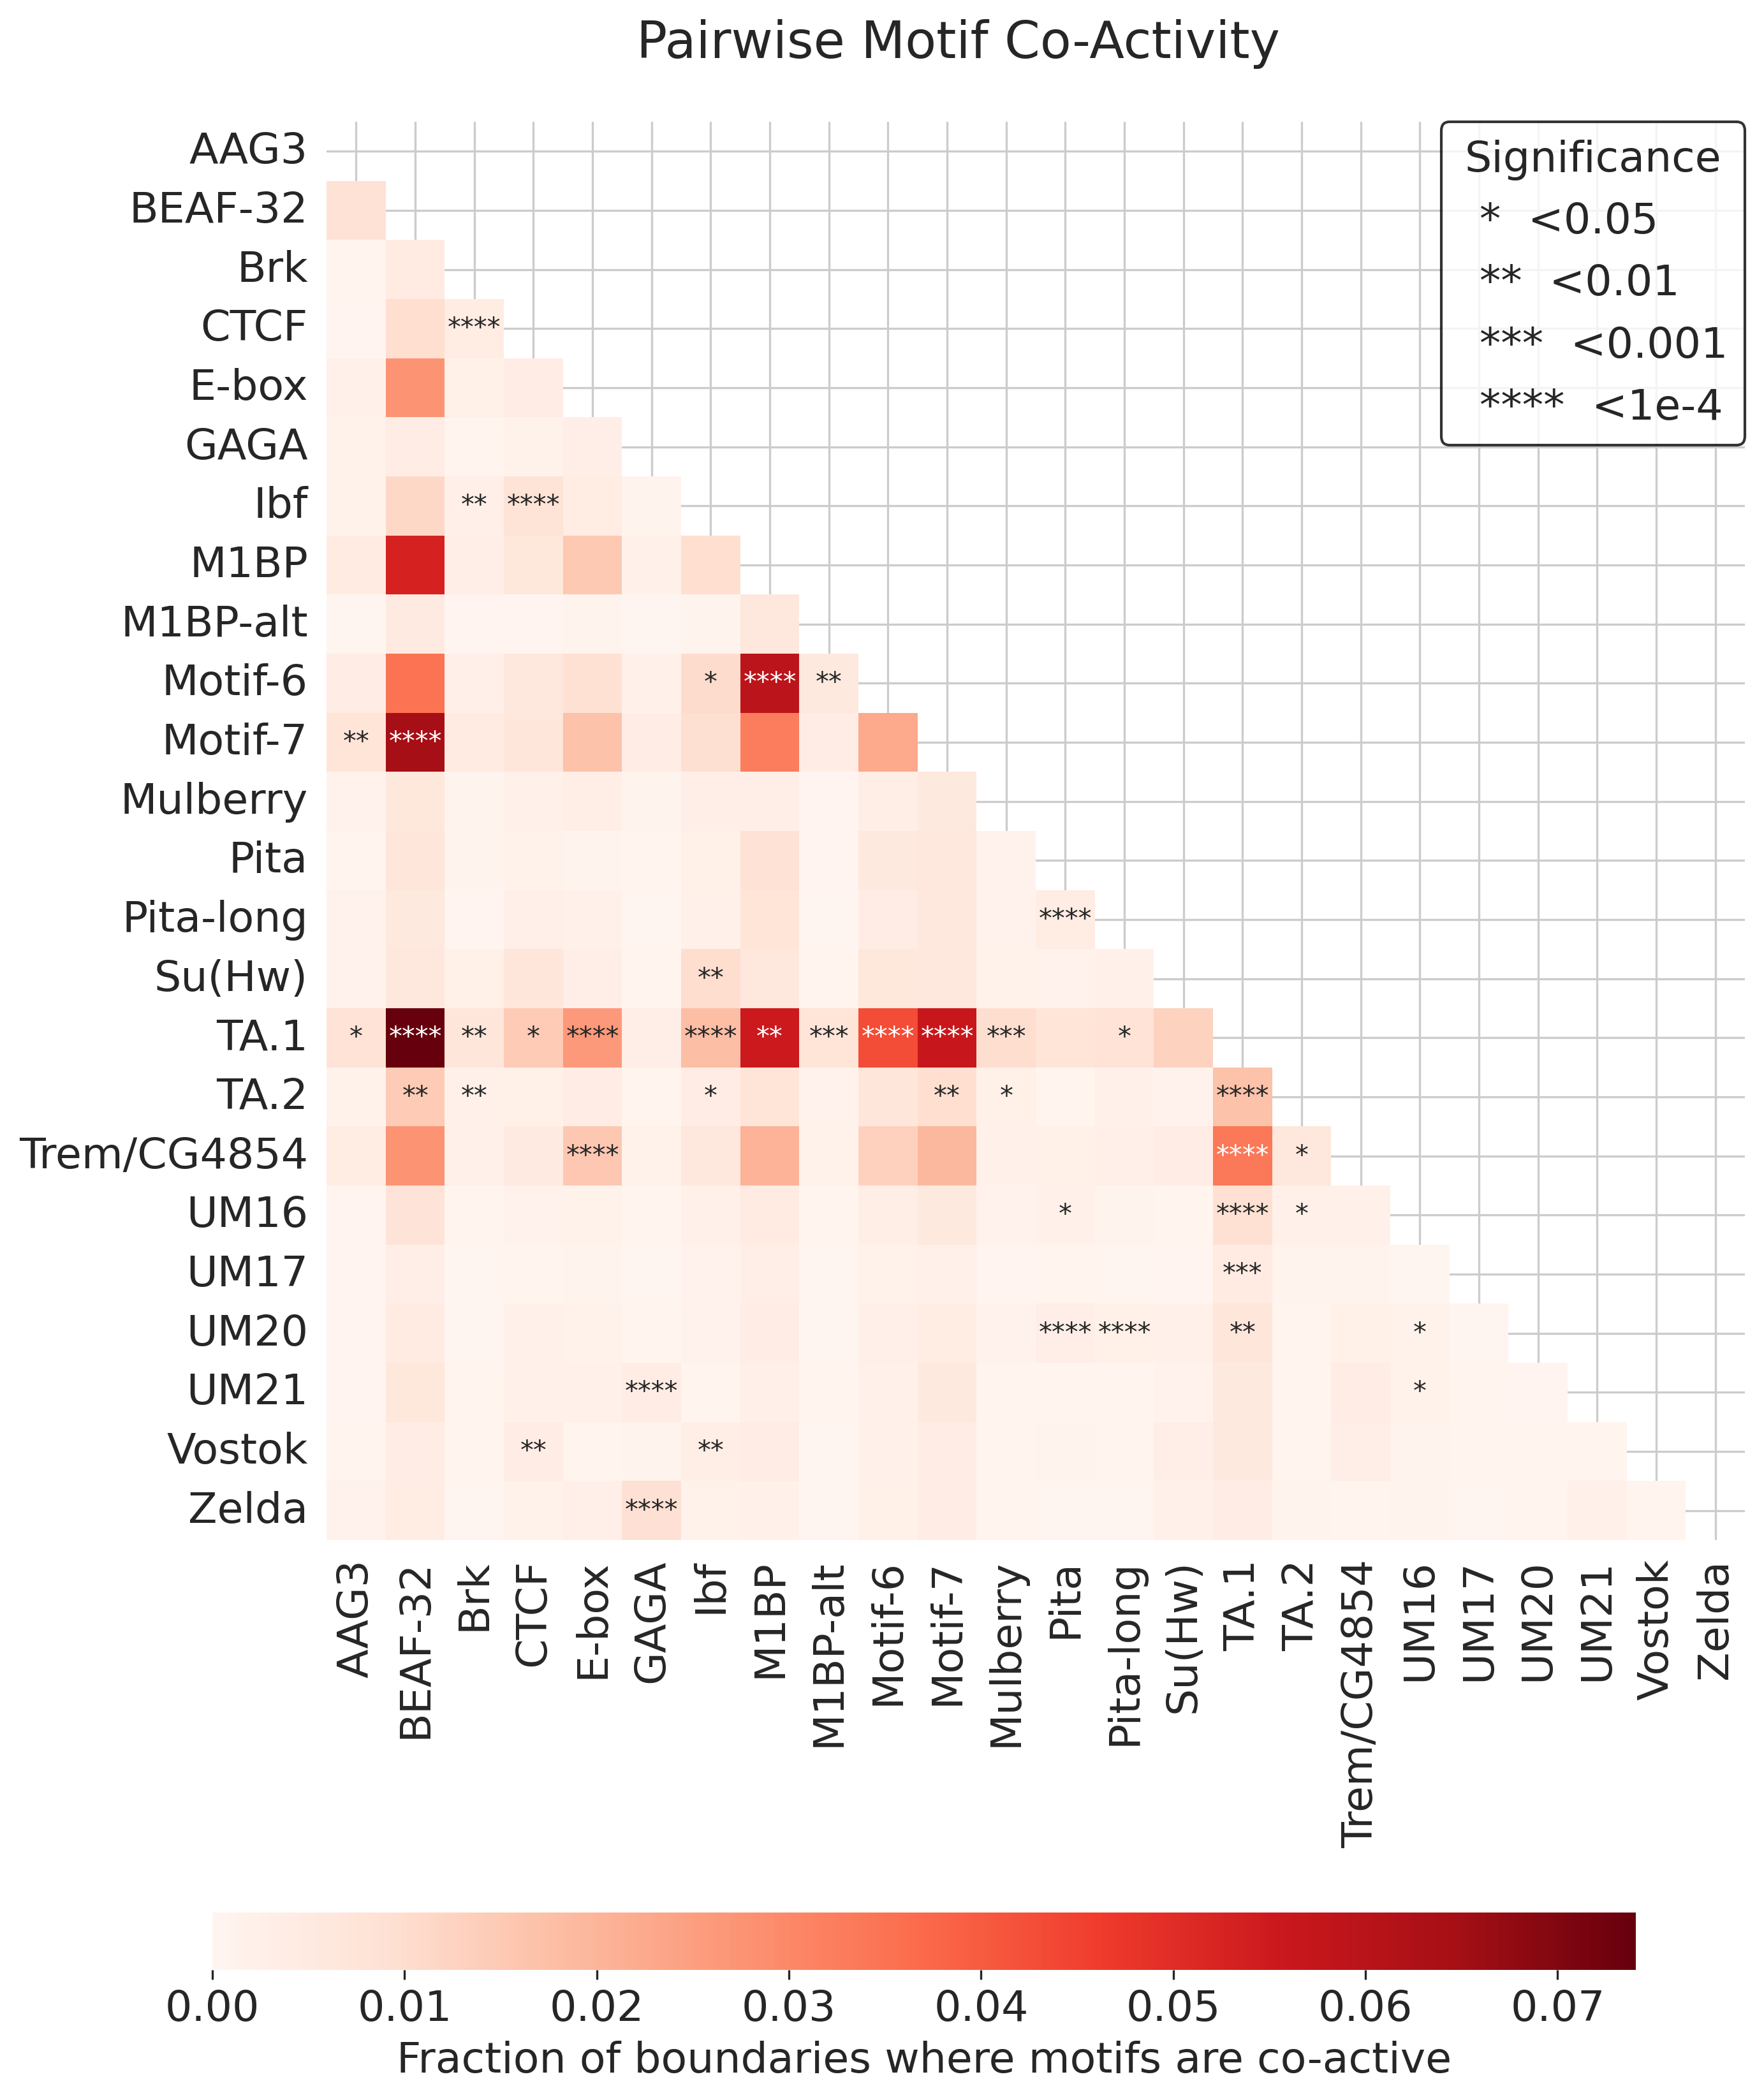

In [45]:
old_rc = plt.rcParams.copy()
plt.rcParams['font.size'] = 16
plot_column('fraction_co_activate', cbar_title='Fraction of boundaries where motifs are co-active', cmap='Reds')

plt.rcParams.update(old_rc)

## Supplementary figures

/tmp/ipykernel_3624397/1776712308.py:36: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels([f'{cluster2annotation[str(c)]}' if str(c) in cluster2annotation else 'Control' for c in sorted_order])


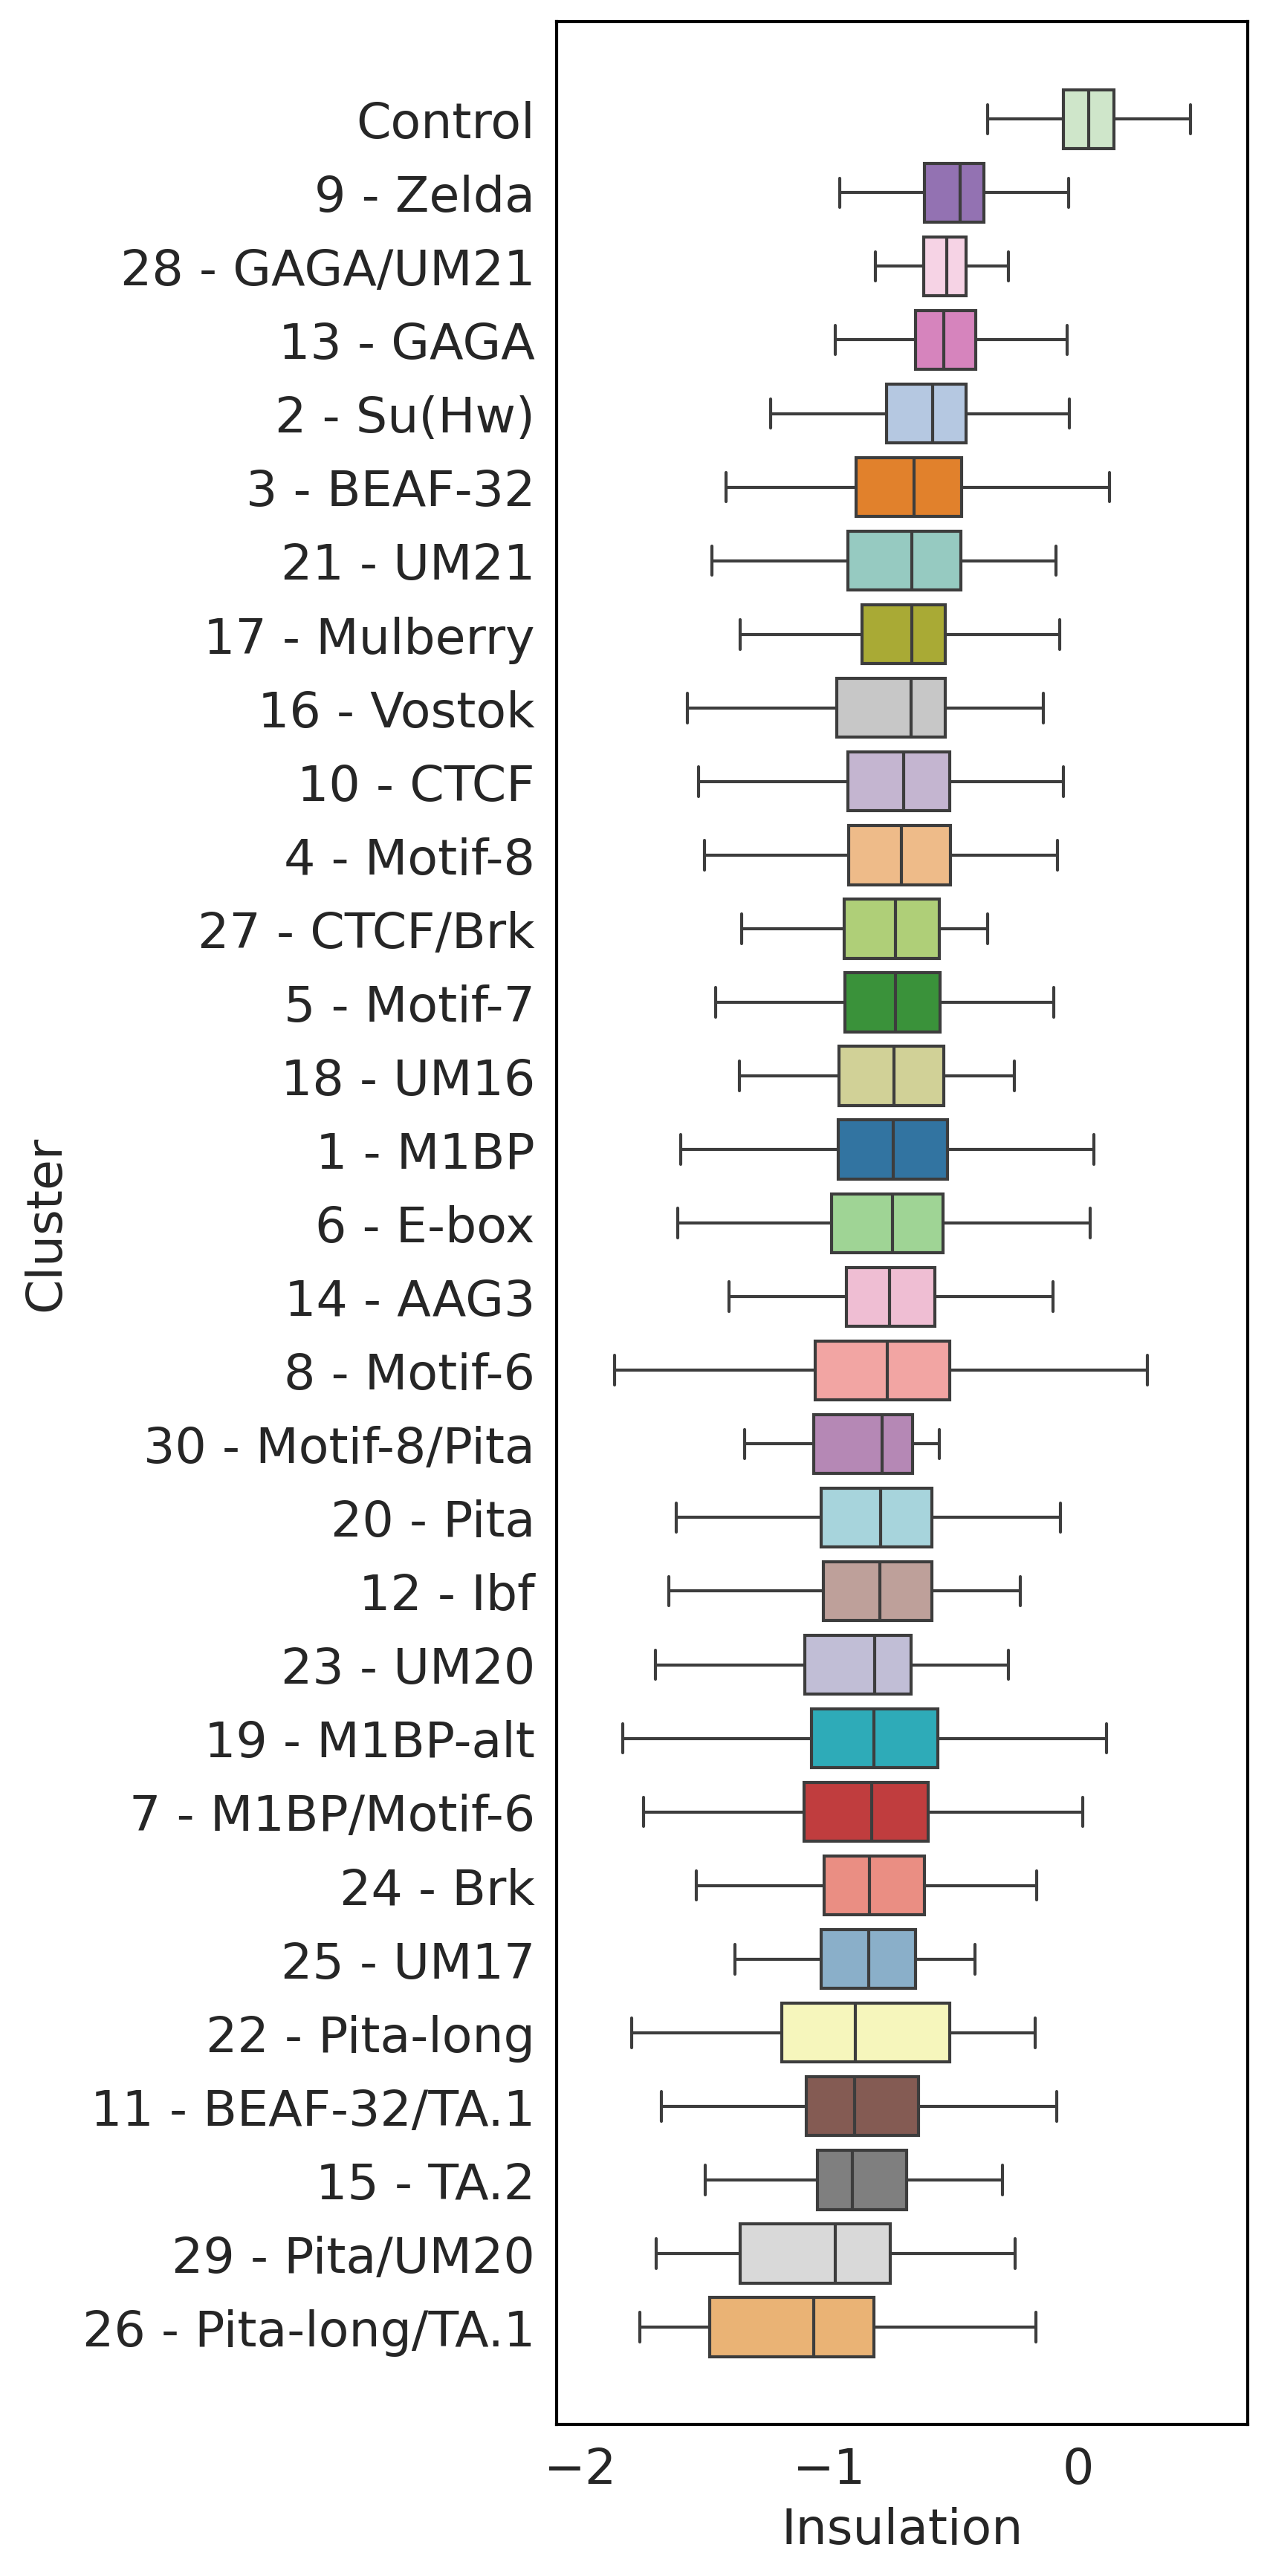

In [46]:
old_rc = plt.rcParams.copy()
plt.rcParams['font.size'] = 16

groups_df = bdf_plot.copy()

non_boundary_examples = pd.concat([TRAIN_df, VAL_df, TEST_df]).reset_index(drop=True).query('boundary == 0').sample(n=len(groups_df), random_state=10)
group_5 = non_boundary_examples['demeaned_ins_score_1'].to_numpy()

tmp1 = bdf_plot.copy()[['cluster','demeaned_ins_score_1']].reset_index(drop=True)
tmp2 = pd.DataFrame({
    'cluster': [30] * len(group_5),
    'demeaned_ins_score_1': list(group_5)
})

boxplot_df = pd.concat([tmp1, tmp2])
boxplot_df

x='demeaned_ins_score_1'
K=30

sorted_percs = boxplot_df.groupby("cluster")[x].median().sort_values(ascending=False)
sorted_order = sorted_percs.index.tolist()

non_boundary_examples = pd.concat([TRAIN_df, VAL_df, TEST_df]).reset_index(drop=True).query('boundary == 0').sample(n=len(groups_df), random_state=10)
group_5 = non_boundary_examples['demeaned_ins_score_1'].to_numpy()

plt.figure(figsize=(4, 14), dpi=300)
ax = sns.boxplot(boxplot_df, showfliers=False, y='cluster', 
                 x=x, hue='cluster', 
                 palette={i: cluster_colors[i] for i in range(K+1)},
                 order=sorted_order,
                 flierprops=dict(marker='o', color='black', markersize=1),
                orient='h')
ax.grid(False)

ax.set_yticklabels([f'{cluster2annotation[str(c)]}' if str(c) in cluster2annotation else 'Control' for c in sorted_order])

for spine in ax.spines:
    ax.spines[spine].set_linewidth(1)
    ax.spines[spine].set_color('black')

ax.margins(x=0.1, y=0.03)  # 10% padding on both axes

ax.tick_params(axis='x')

plt.xlabel('Insulation')
plt.ylabel('Cluster')

ax.get_legend().remove()

handles, labels = ax.get_legend_handles_labels()
plt.show()

plt.rcParams.update(old_rc)

In [47]:
ref_pth = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/annotations/dm6.refGene.gtf'

annotations_df = pd.read_csv(ref_pth, sep='\t', comment='#', header=None)
annotations_df.columns = ['chrom', 'source', 'feature', 'start', 'end', 'score', 'strand', 'frame', 'attribute']
annotations_df['length'] = annotations_df['end'] - annotations_df['start']

chroms_list = bdf_plot.chrom.value_counts().index.tolist()

annotations_filtered = annotations_df.query('chrom.isin(@chroms_list)').reset_index(drop=True)
annotations_filtered['gene_id'] = annotations_filtered['attribute'].str.extract(r'gene_id "([^"]+)"')
annotations_filtered['transcript_id'] = annotations_filtered['attribute'].str.extract(r'transcript_id "([^"]+)"')
annotations_filtered['gene_name'] = annotations_filtered['attribute'].str.extract(r'gene_name "([^"]+)"')
annotations_filtered.drop('attribute', axis=1, inplace=True)

tss_df = annotations_filtered.query('feature == "transcript" and transcript_id.str.contains("NM") or transcript_id.str.contains("NP")') # filter for protein coding genes
tss_df = tss_df.drop_duplicates('gene_name').reset_index(drop=True)

tss_pos = []
for i, row in tss_df.iterrows():
    if row.strand == "+": tss_pos.append(tss_df.loc[i, 'start'])
    if row.strand == "-": tss_pos.append(tss_df.loc[i, 'end'])
tss_df['tss_position'] = tss_pos

tss_query = tss_df[['chrom', 'tss_position', 'gene_name', 'strand']]

# query radius
print('num genes', tss_query.shape)
print('num boundaries', bdf_plot.shape)

num genes (13916, 4)
num boundaries (4289, 20)


In [48]:
def contains_tss(row, query_radius):
    matches = tss_query[
        (tss_query['chrom'] == row['chrom']) &
        (tss_query['tss_position'] >= row['start'] - query_radius - 1)  &
        (tss_query['tss_position'] <= row['end'] + query_radius)  # half-open interval convention
    ]
    return not matches.empty

def prox_genes(row, query_radius):
    matches = tss_query[
        (tss_query['chrom'] == row['chrom']) &
        (tss_query['tss_position'] >= row['start'] - query_radius - 1) &
        (tss_query['tss_position'] <= row['end'] + query_radius)  # half-open interval convention
    ]
    gene_list = ' '.join(matches.gene_name.tolist()) if row.contains_tss else None
    return gene_list

def num_prox_genes(row, query_radius):
    matches = tss_query[
        (tss_query['chrom'] == row['chrom']) &
        (tss_query['tss_position'] >= row['start'] - query_radius - 1) &
        (tss_query['tss_position'] <= row['end'] + query_radius)  # half-open interval convention
    ]
    gene_list = ' '.join(matches.gene_name.tolist()) if row.contains_tss else None
    return len(matches.gene_name.tolist()) if gene_list else 0

def last_tss(row, query_radius):
    matches = tss_query[
        (tss_query['chrom'] == row['chrom']) &
        (tss_query['tss_position'] >= row['start'] - query_radius - 1)  &
        (tss_query['tss_position'] <= row['end'] + query_radius)  # half-open interval convention
    ]
    if not matches.empty:
        # return ','.join(str(num) for num in matches.tss_position.tolist())
        return int(matches.iloc[-1].tss_position)
    return -1

def tss_direction(row, query_radius):
    matches = tss_query[
        (tss_query['chrom'] == row['chrom']) &
        (tss_query['tss_position'] >= row['start'] - query_radius - 1)  &
        (tss_query['tss_position'] <= row['end'] + query_radius)  # half-open interval convention
    ]
    if not matches.empty:
        # return ','.join(str(num) for num in matches.tss_position.tolist())
        return str(matches.iloc[-1].strand)
    return None
    
def tss_all_positions(row, query_radius):
    matches = tss_query[
        (tss_query['chrom'] == row['chrom']) &
        (tss_query['tss_position'] >= row['start'] - query_radius - 1)  &
        (tss_query['tss_position'] <= row['end'] + query_radius)  # half-open interval convention
    ]
    tss_positions = ' '.join([str(i) for i in matches.tss_position]) if row.contains_tss else None
    return tss_positions

def tss_all_directions(row, query_radius):
    matches = tss_query[
        (tss_query['chrom'] == row['chrom']) &
        (tss_query['tss_position'] >= row['start'] - query_radius - 1)  &
        (tss_query['tss_position'] <= row['end'] + query_radius)  # half-open interval convention
    ]
    tss_directions = ' '.join([str(i) for i in matches.strand]) if row.contains_tss else None
    return tss_directions



query_radius = 1000 # 1kb
bdf_plot['contains_tss'] = bdf_plot.apply(contains_tss, query_radius=query_radius, axis=1)


/tmp/ipykernel_3624397/1734972252.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y='cluster', x='prop_near_tss', data=frequency_df, ax=ax, palette={str(i): cluster_colors[i] for i in range(K)})
/tmp/ipykernel_3624397/1734972252.py:20: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels([f'{cluster2annotation[str(c)]}' for c in frequency_df.cluster])


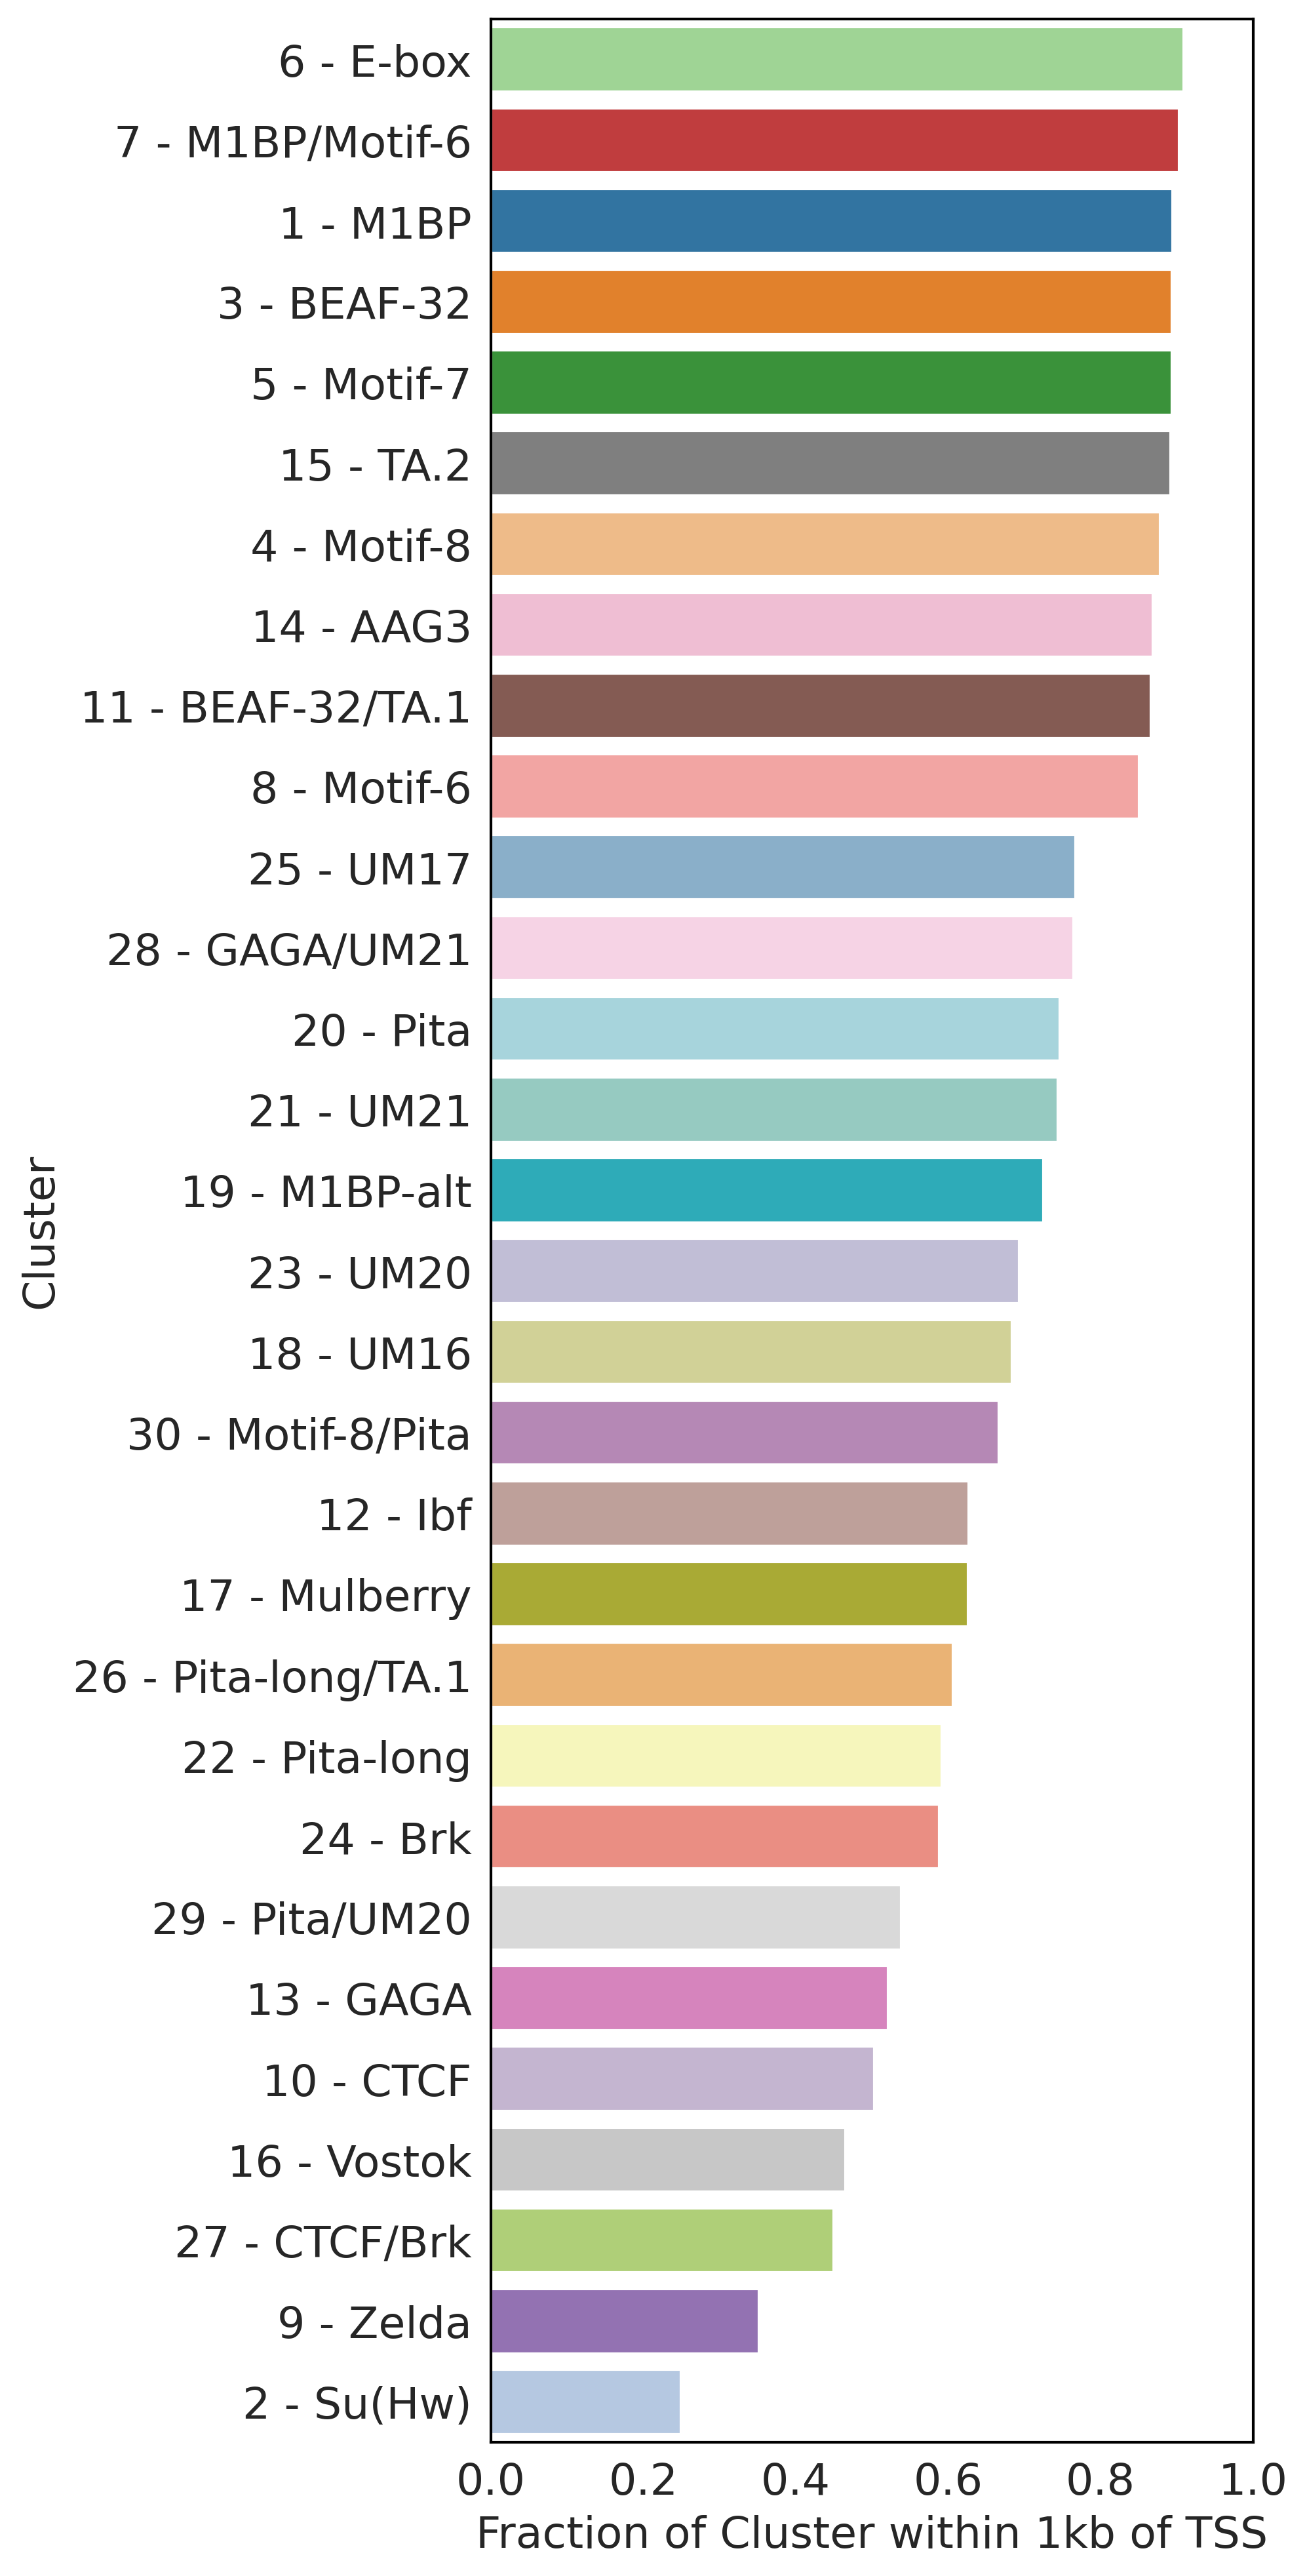

In [49]:
old_rc = plt.rcParams.copy()
plt.rcParams['font.size'] = 16

frequency_series = bdf_plot.groupby('cluster').contains_tss.mean()
frequency_df = pd.DataFrame({
    'cluster': [str(i) for i in frequency_series.index],
    'prop_near_tss': frequency_series,
}).sort_values('prop_near_tss', ascending=False)


fig, ax = plt.subplots(figsize=(5, 16), dpi=300)
sns.barplot(y='cluster', x='prop_near_tss', data=frequency_df, ax=ax, palette={str(i): cluster_colors[i] for i in range(K)})

plt.grid(False)
plt.xlabel("Fraction of Cluster within 1kb of TSS")

plt.xlim([0,1])
plt.ylabel('Cluster')

ax.set_yticklabels([f'{cluster2annotation[str(c)]}' for c in frequency_df.cluster])

for spine in ax.spines:
    ax.spines[spine].set_linewidth(1)
    ax.spines[spine].set_color('black')
# plt.savefig('freq_clusters.pdf')
plt.show()

plt.rcParams.update(old_rc)